# Machine Learning-Based Credit Card Fraud Detection on Imbalanced Data

**Objective:** detect fraudulent credit card transactions when fraud is only ~0.17% of the data.

**Dataset:** Kaggle "Credit Card Fraud Detection" (ULB): 284,807 European card transactions
over two days, 492 frauds. Features V1–V28 are PCA-transformed; Time and Amount are raw.

**Models:**
- Main: Decision Tree and Random Forest
- Comparison: Logistic Regression, XGBoost (GPU), LightGBM

**Approach:** EDA → preprocessing → baselines → imbalance handling (class weights,
undersampling, SMOTE) → hyperparameter tuning → threshold tuning → model comparison.

**Metrics:** precision, recall, F1 and PR-AUC on the fraud class (accuracy is misleading here).

**Key result:** tuned XGBoost was best (PR-AUC 0.836, F1 0.862); among the main models,
the Random Forest clearly beat the Decision Tree (PR-AUC 0.824 vs 0.709).

## Contents
- **Step 1:** Load and explore the data
- **Step 2:** Exploratory data analysis (EDA)
- **Step 3:** Preprocessing
- **Steps 4 & 5:** Baseline models and evaluation metrics
- **Step 6:** Handling the class imbalance
- **Step 7:** Hyperparameter tuning
- **Step 8:** Threshold tuning
- **Step 9:** Feature importance, final comparison and conclusion (Decision Tree vs Random Forest)
- **Step 10:** More models: Logistic Regression, XGBoost, LightGBM
- **Final Conclusion**

---

## Step 1: Load and Explore the Data

In [1]:
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)

df = pd.read_csv("creditcard.csv")
print("Shape:", df.shape)
df.head()

Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [3]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,2.238554e-15,1.724421e-15,-1.245415e-15,8.238900e-16,1.213481e-15,4.866699e-15,1.436219e-15,-3.768179e-16,9.707851e-16,1.036249e-15,6.418678e-16,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,1.088850e+00,1.020713e+00,9.992014e-01,9.952742e-01,9.585956e-01,9.153160e-01,8.762529e-01,8.493371e-01,8.381762e-01,8.140405e-01,7.709250e-01,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,-2.458826e+01,-4.797473e+00,-1.868371e+01,-5.791881e+00,-1.921433e+01,-4.498945e+00,-1.412985e+01,-2.516280e+01,-9.498746e+00,-7.213527e+00,-5.449772e+01,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,-5.354257e-01,-7.624942e-01,-4.055715e-01,-6.485393e-01,-4.255740e-01,-5.828843e-01,-4.680368e-01,-4.837483e-01,-4.988498e-01,-4.562989e-01,-2.117214e-01,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,-9.291738e-02,-3.275735e-02,1.400326e-01,-1.356806e-02,5.060132e-02,4.807155e-02,6.641332e-02,-6.567575e-02,-3.636312e-03,3.734823e-03,-6.248109e-02,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,4.539234e-01,7.395934e-01,6.182380e-01,6.625050e-01,4.931498e-01,6.488208e-01,5.232963e-01,3.996750e-01,5.008067e-01,4.589494e-01,1.330408e-01,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,2.374514e+01,1.201891e+01,7.848392e+00,7.126883e+00,1.052677e+01,8.877742e+00,1.731511e+01,9.253526e+00,5.041069e+00,5.591971e+00,3.942090e+01,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [4]:
print("Missing values in total:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values in total: 0
Duplicate rows: 1081


In [5]:
counts = df["Class"].value_counts()
percent = df["Class"].value_counts(normalize=True) * 100

class_summary = pd.DataFrame({"count": counts, "percent": percent.round(3)})
class_summary.index = class_summary.index.map({0: "Normal (0)", 1: "Fraud (1)"})
print(class_summary)
print(f"\nImbalance ratio: 1 fraud per {counts[0] // counts[1]} normal transactions")

             count  percent
Class                      
Normal (0)  284315   99.827
Fraud (1)      492    0.173

Imbalance ratio: 1 fraud per 577 normal transactions


In [6]:
# Amount and Time are the only non-PCA features; compare them by class
df.groupby("Class")[["Amount", "Time"]].describe().T

Class                     0              1
Amount count  284315.000000     492.000000
       mean       88.291022     122.211321
       std       250.105092     256.683288
       min         0.000000       0.000000
       25%         5.650000       1.000000
       50%        22.000000       9.250000
       75%        77.050000     105.890000
       max     25691.160000    2125.870000
Time   count  284315.000000     492.000000
       mean    94838.202258   80746.806911
       std     47484.015786   47835.365138
       min         0.000000     406.000000
       25%     54230.000000   41241.500000
       50%     84711.000000   75568.500000
       75%    139333.000000  128483.000000
       max    172792.000000  170348.000000

### Observations

- `V1`–`V28` are PCA-transformed features (anonymized for privacy).
- `Time` = seconds since the first transaction; `Amount` = transaction amount.
- `Class` is the target: 1 = fraud, 0 = normal.
- The data is highly imbalanced (~0.17% fraud), so accuracy is not a useful metric.
- No missing values, but some duplicate rows (handled in Step 2).

## Step 2: Exploratory Data Analysis (EDA)

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Remove exact duplicate rows found in Step 1
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)
print(df["Class"].value_counts())

Shape after removing duplicates: (283726, 31)
Class
0    283253
1       473
Name: count, dtype: int64


### 2.1 Class distribution

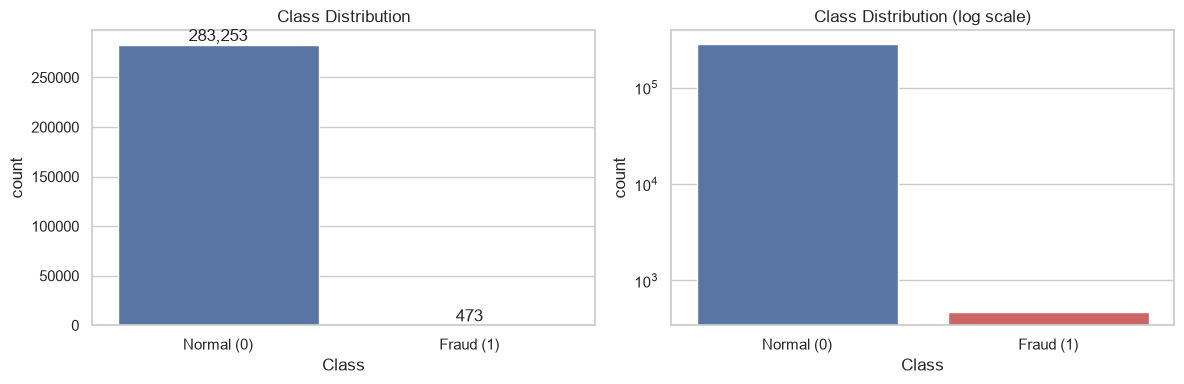

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = sns.countplot(x="Class", data=df, ax=axes[0], palette=["#4C72B0", "#DD5555"], hue="Class", legend=False)
ax.set_xticks([0, 1], ["Normal (0)", "Fraud (1)"])
ax.set_title("Class Distribution")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")

# Log scale makes the small fraud bar visible
ax = sns.countplot(x="Class", data=df, ax=axes[1], palette=["#4C72B0", "#DD5555"], hue="Class", legend=False)
ax.set_yscale("log")
ax.set_xticks([0, 1], ["Normal (0)", "Fraud (1)"])
ax.set_title("Class Distribution (log scale)")

plt.tight_layout()
plt.show()

### 2.2 Transaction amount

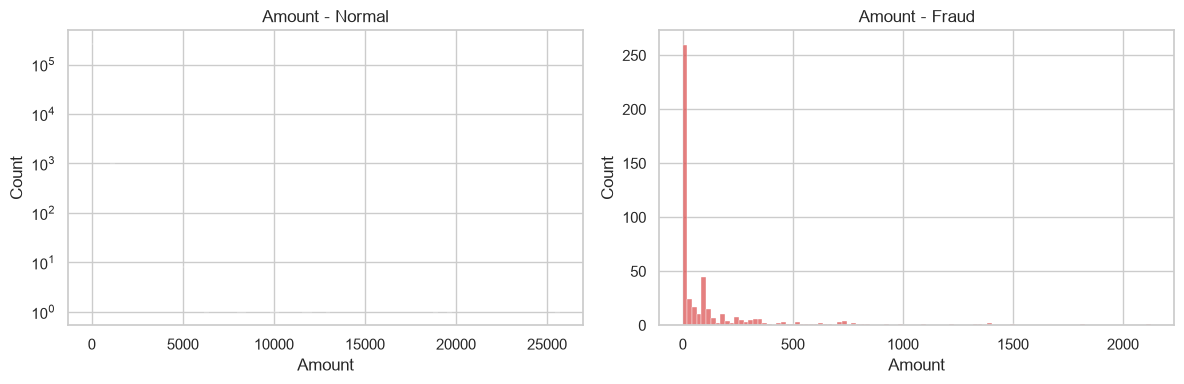

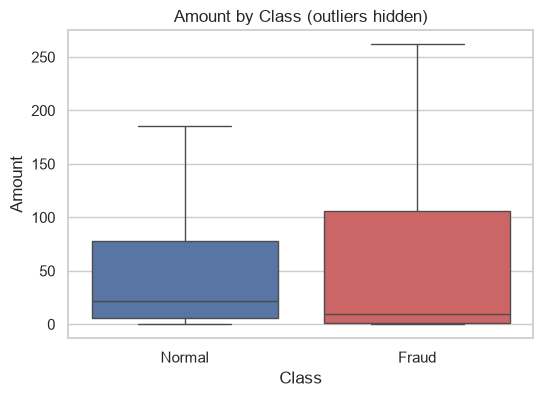

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df.loc[df["Class"] == 0, "Amount"], bins=100, ax=axes[0], color="#4C72B0", log_scale=(False, True))
axes[0].set_title("Amount - Normal")

sns.histplot(df.loc[df["Class"] == 1, "Amount"], bins=100, ax=axes[1], color="#DD5555")
axes[1].set_title("Amount - Fraud")

plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
sns.boxplot(x="Class", y="Amount", data=df, showfliers=False, hue="Class", palette=["#4C72B0", "#DD5555"], legend=False)
plt.xticks([0, 1], ["Normal", "Fraud"])
plt.title("Amount by Class (outliers hidden)")
plt.show()

### 2.3 Transaction time

`Time` covers two days (~172,800 seconds). We convert it to hour of day to look for patterns.

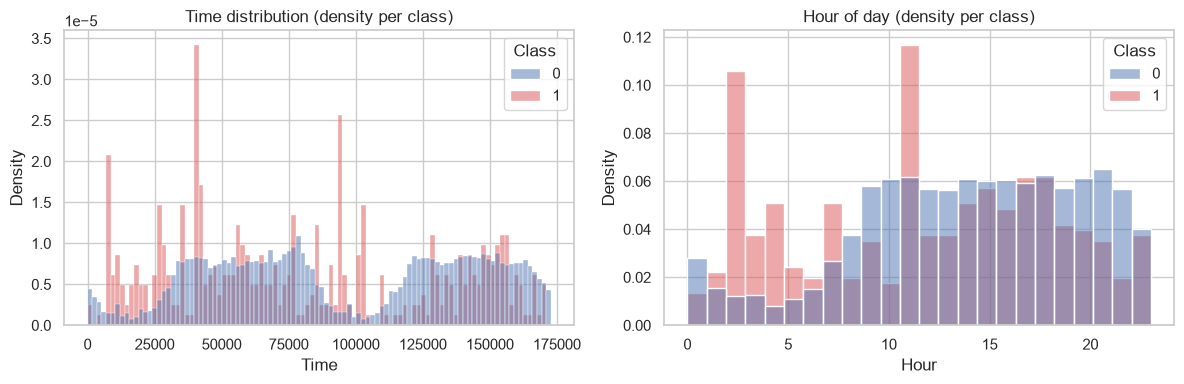

In [10]:
df["Hour"] = (df["Time"] // 3600) % 24

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=df, x="Time", hue="Class", bins=100, stat="density", common_norm=False, ax=axes[0], palette=["#4C72B0", "#DD5555"])
axes[0].set_title("Time distribution (density per class)")

sns.histplot(data=df, x="Hour", hue="Class", bins=24, stat="density", common_norm=False, ax=axes[1], palette=["#4C72B0", "#DD5555"])
axes[1].set_title("Hour of day (density per class)")

plt.tight_layout()
plt.show()

### 2.4 Correlation with the target

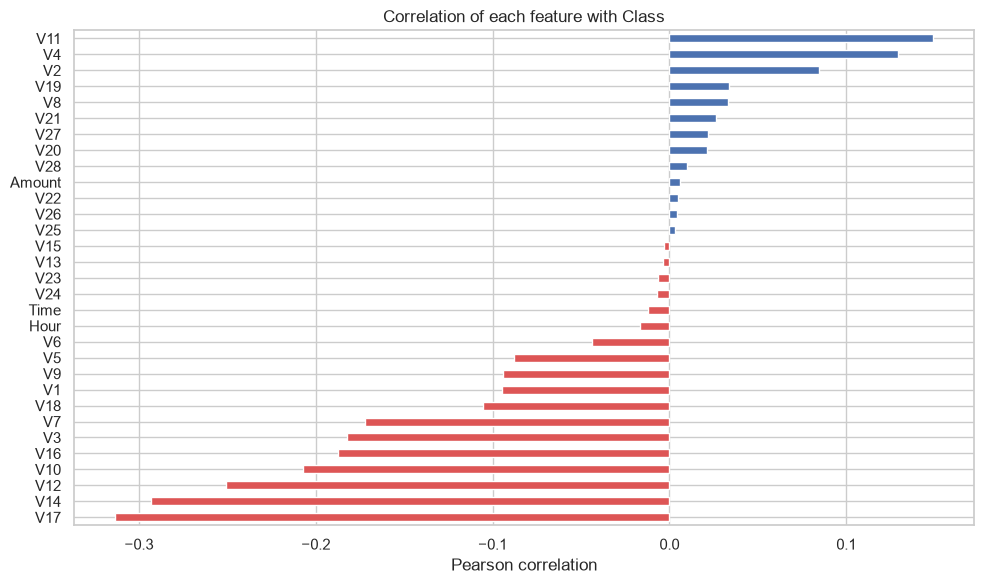

Most negative:
 V17   -0.313498
V14   -0.293375
V12   -0.250711
V10   -0.206971
V16   -0.187186
dtype: float64

Most positive:
 V8     0.033068
V19    0.033631
V2     0.084624
V4     0.129326
V11    0.149067
dtype: float64


In [11]:
corr_with_class = df.drop(columns=["Class"]).corrwith(df["Class"]).sort_values()

plt.figure(figsize=(10, 6))
colors = ["#DD5555" if c < 0 else "#4C72B0" for c in corr_with_class]
corr_with_class.plot(kind="barh", color=colors)
plt.title("Correlation of each feature with Class")
plt.xlabel("Pearson correlation")
plt.tight_layout()
plt.show()

print("Most negative:\n", corr_with_class.head(5))
print("\nMost positive:\n", corr_with_class.tail(5))

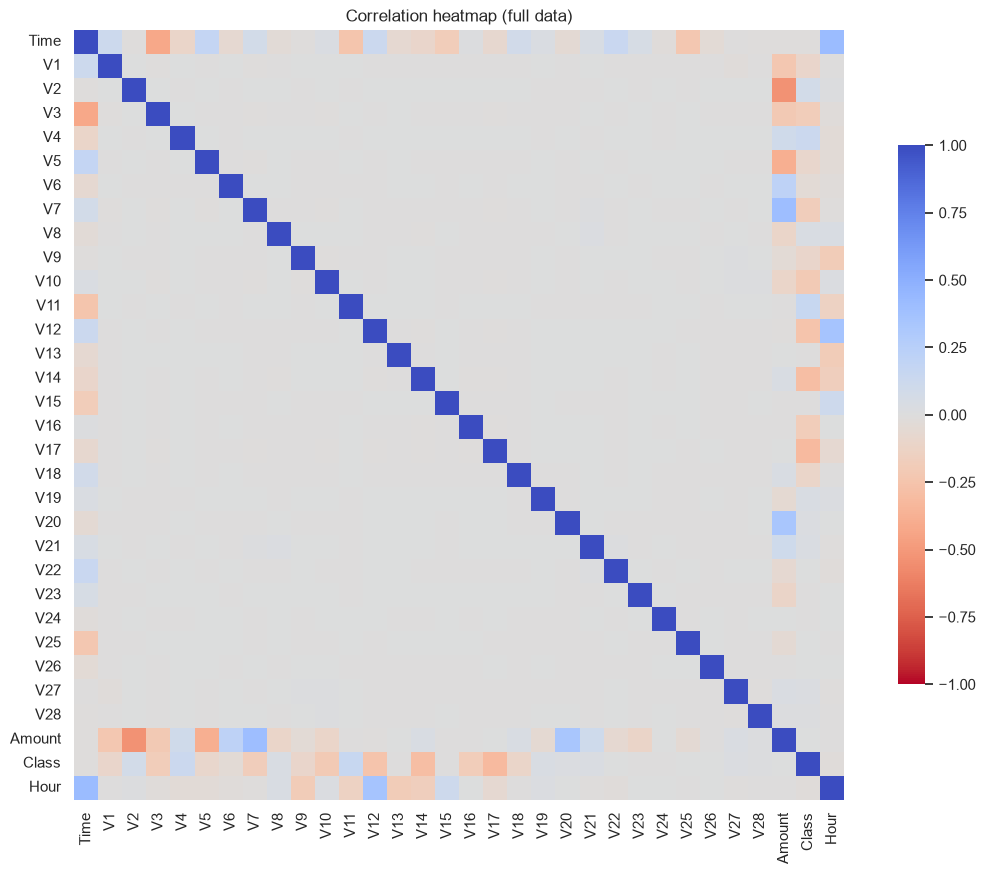

In [12]:
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(), cmap="coolwarm_r", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.7})
plt.title("Correlation heatmap (full data)")
plt.show()

### 2.5 Distributions of the most important features

Top features: ['V17', 'V14', 'V12', 'V10', 'V16', 'V3']


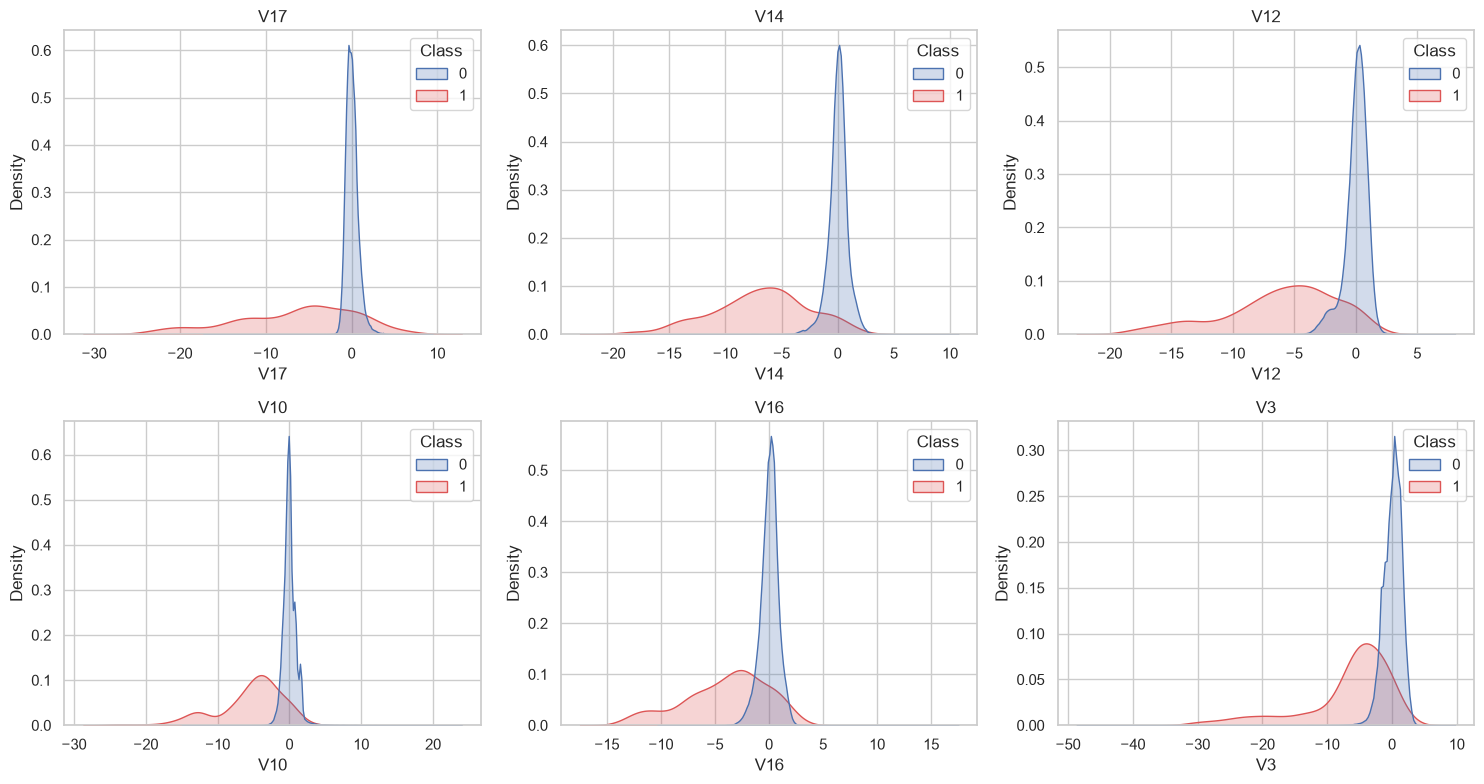

In [13]:
top_features = corr_with_class.abs().sort_values(ascending=False).head(6).index.tolist()
print("Top features:", top_features)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, top_features):
    sns.kdeplot(data=df, x=col, hue="Class", common_norm=False, fill=True, ax=ax, palette=["#4C72B0", "#DD5555"])
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [14]:
# Hour was only for EDA; drop it so the feature set stays the original one
df = df.drop(columns=["Hour"])

### Observations

- After removing duplicates, fraud is still ~0.17% of transactions: extreme class imbalance.
- Fraud amounts are usually small; most are under ~$100, though a few are large.
- Normal transactions follow a clear day/night cycle; fraud is spread more evenly across hours, so it is relatively more common at night.
- Features such as `V17`, `V14`, `V12`, `V10` (negative) and `V11`, `V4` (positive) have the strongest correlation with fraud.
- The `V` features are almost uncorrelated with each other because they come from PCA.

## Step 3: Preprocessing

1. Split features (`X`) and target (`y`).
2. Stratified train/test split (80/20) so both sets keep the same fraud ratio.
3. Scale `Time` and `Amount` with `RobustScaler` (robust to the large outliers in `Amount`).
   The scaler is fitted on the **training set only** to avoid data leakage.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler

RANDOM_STATE = 42

X = df.drop(columns=["Class"])
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (226980, 30)  Test: (56746, 30)


In [16]:
split_summary = pd.DataFrame({
    "rows": [len(y_train), len(y_test)],
    "frauds": [y_train.sum(), y_test.sum()],
    "fraud %": [y_train.mean() * 100, y_test.mean() * 100],
}, index=["Train", "Test"]).round(3)
split_summary

,rows,frauds,fraud %
Train,226980,378,0.167
Test,56746,95,0.167


In [17]:
scale_cols = ["Time", "Amount"]

scaler = RobustScaler()
X_train = X_train.copy()
X_test = X_test.copy()
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test[scale_cols] = scaler.transform(X_test[scale_cols])

X_train[scale_cols].describe().round(3)

,Time,Amount
count,226980.000,226980.000
mean,0.118,0.919
std,0.558,3.406
min,-0.996,-0.306
25%,-0.359,-0.227
50%,0.000,0.000
75%,0.641,0.773
max,1.034,272.096


### Observations

- The train and test sets have the same fraud percentage (~0.17%) thanks to `stratify=y`.
- The test set is kept untouched until final evaluation; any resampling (Step 6) is applied to the training set only.
- Tree models do not need scaling, but scaling `Time` and `Amount` keeps all features on a similar range, matching the PCA features `V1`–`V28`.

## Step 4 & 5: Baseline Models and Evaluation Metrics

We first train both models on the raw (imbalanced) training data with default settings. This gives a baseline to compare against once we handle the imbalance in Step 6.

**Metrics** (accuracy is misleading here: predicting "normal" for everything already gives 99.83%):
- **Precision**: of the transactions flagged as fraud, how many really are fraud.
- **Recall**: of all real frauds, how many we caught. Most important here, since a missed fraud is costly.
- **F1-score**: balance between precision and recall.
- **PR-AUC (average precision)**: area under the precision-recall curve; the best single metric for imbalanced data.
- **ROC-AUC**: reported for completeness, but it looks optimistic on imbalanced data.

In [18]:
import time
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
)

results = []  # one row per model, collected across all steps


def evaluate(name, model, X_test, y_test, train_time=None):
    """Print the metrics and confusion matrix for a fitted model and store them in results."""
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "PR-AUC": average_precision_score(y_test, y_prob),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Train time (s)": train_time,
    }
    results[:] = [r for r in results if r["Model"] != name] + [row]

    print(f"=== {name} ===")
    print(classification_report(y_test, y_pred, target_names=["Normal", "Fraud"], digits=4))
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Normal", "Fraud"]).plot(cmap="Blues", values_format="d")
    plt.title(name)
    plt.grid(False)
    plt.show()
    return row

### 4.1 Baseline Decision Tree

Training time: 7.9 s, tree depth: 23, leaves: 150
=== Decision Tree (baseline) ===
              precision    recall  f1-score   support

      Normal     0.9995    0.9995    0.9995     56651
       Fraud     0.7204    0.7053    0.7128        95

    accuracy                         0.9990     56746
   macro avg     0.8600    0.8524    0.8561     56746
weighted avg     0.9990    0.9990    0.9990     56746



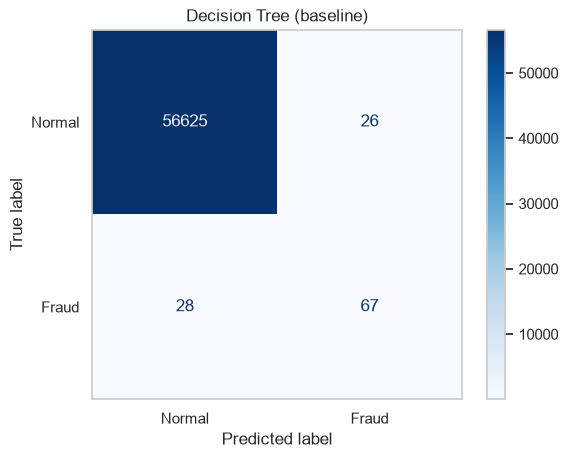

In [19]:
dt_base = DecisionTreeClassifier(random_state=RANDOM_STATE)

start = time.time()
dt_base.fit(X_train, y_train)
dt_time = time.time() - start
print(f"Training time: {dt_time:.1f} s, tree depth: {dt_base.get_depth()}, leaves: {dt_base.get_n_leaves()}")

evaluate("Decision Tree (baseline)", dt_base, X_test, y_test, dt_time);

### 4.2 Baseline Random Forest

Training time: 6.2 s
=== Random Forest (baseline) ===
              precision    recall  f1-score   support

      Normal     0.9995    1.0000    0.9998     56651
       Fraud     0.9718    0.7263    0.8313        95

    accuracy                         0.9995     56746
   macro avg     0.9857    0.8631    0.9155     56746
weighted avg     0.9995    0.9995    0.9995     56746



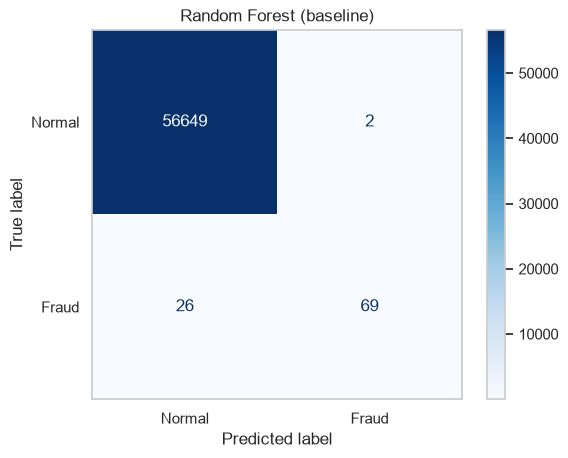

In [20]:
rf_base = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE)

start = time.time()
rf_base.fit(X_train, y_train)
rf_time = time.time() - start
print(f"Training time: {rf_time:.1f} s")

evaluate("Random Forest (baseline)", rf_base, X_test, y_test, rf_time);

### 4.3 Baseline comparison

In [21]:
results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df

,Accuracy,Precision,Recall,F1,PR-AUC,ROC-AUC,Train time (s)
Model,,,,,,,
Decision Tree (baseline),0.9990,0.7204,0.7053,0.7128,0.5086,0.8524,7.8860
Random Forest (baseline),0.9995,0.9718,0.7263,0.8313,0.7876,0.9239,6.2227


### Observations

- Both models reach ~99.9% accuracy, which only shows that accuracy is not useful on this data.
- The precision, recall and F1 for the **fraud class** are what actually separate the models.
- The Random Forest usually beats the single Decision Tree on precision and PR-AUC because averaging many trees reduces overfitting.
- Some frauds are still missed (false negatives in the confusion matrix). Step 6 tries to raise recall by handling the class imbalance.

## Step 6: Handling the Class Imbalance

We compare three techniques, each with both models:

1. **Class weights** (`class_weight="balanced"`): errors on the fraud class cost more during training. No data is changed.
2. **Random undersampling**: randomly drop normal transactions until both classes are equal in the training set.
3. **SMOTE** (Synthetic Minority Over-sampling Technique): create synthetic fraud samples by interpolating between real neighbouring frauds.

Resampling is applied **only to the training data**, inside an `imblearn` `Pipeline`. The test set keeps its real ~0.17% fraud ratio.

In [22]:
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE


def make_dt(**kwargs):
    return DecisionTreeClassifier(random_state=RANDOM_STATE, **kwargs)


def make_rf(**kwargs):
    return RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE, **kwargs)


def train_and_evaluate(name, model):
    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start
    print(f"Training time: {train_time:.1f} s")
    evaluate(name, model, X_test, y_test, train_time)
    return model

### 6.1 Class weights

Training time: 3.4 s
=== Decision Tree + class weights ===
              precision    recall  f1-score   support

      Normal     0.9994    0.9996    0.9995     56651
       Fraud     0.7349    0.6421    0.6854        95

    accuracy                         0.9990     56746
   macro avg     0.8672    0.8209    0.8424     56746
weighted avg     0.9990    0.9990    0.9990     56746



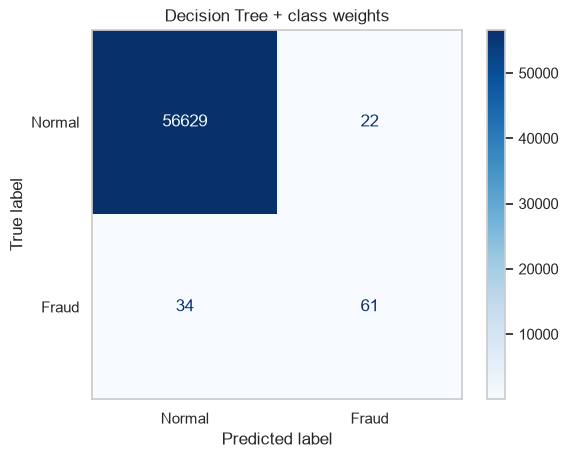

In [23]:
dt_weighted = train_and_evaluate("Decision Tree + class weights", make_dt(class_weight="balanced"))

Training time: 2.5 s
=== Random Forest + class weights ===
              precision    recall  f1-score   support

      Normal     0.9995    0.9999    0.9997     56651
       Fraud     0.9452    0.7263    0.8214        95

    accuracy                         0.9995     56746
   macro avg     0.9724    0.8631    0.9106     56746
weighted avg     0.9995    0.9995    0.9994     56746



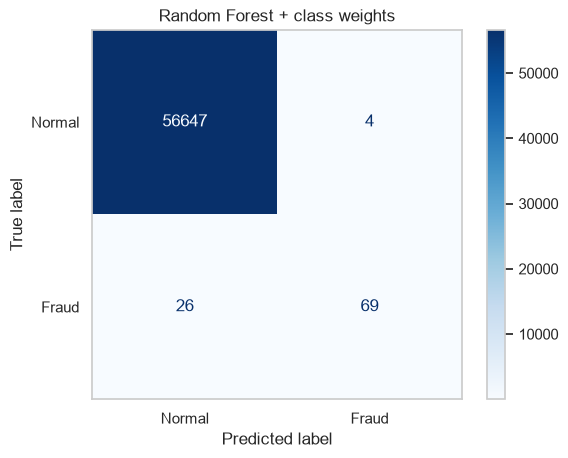

In [24]:
rf_weighted = train_and_evaluate("Random Forest + class weights", make_rf(class_weight="balanced"))

### 6.2 Random undersampling

In [25]:
rus = RandomUnderSampler(random_state=RANDOM_STATE)
X_rus, y_rus = rus.fit_resample(X_train, y_train)
print("Training set after undersampling:", X_rus.shape, dict(y_rus.value_counts()))

Training set after undersampling: (756, 30) {0: np.int64(378), 1: np.int64(378)}


Training time: 0.0 s
=== Decision Tree + undersampling ===
              precision    recall  f1-score   support

      Normal     0.9999    0.8964    0.9453     56651
       Fraud     0.0149    0.9368    0.0294        95

    accuracy                         0.8965     56746
   macro avg     0.5074    0.9166    0.4874     56746
weighted avg     0.9982    0.8965    0.9438     56746



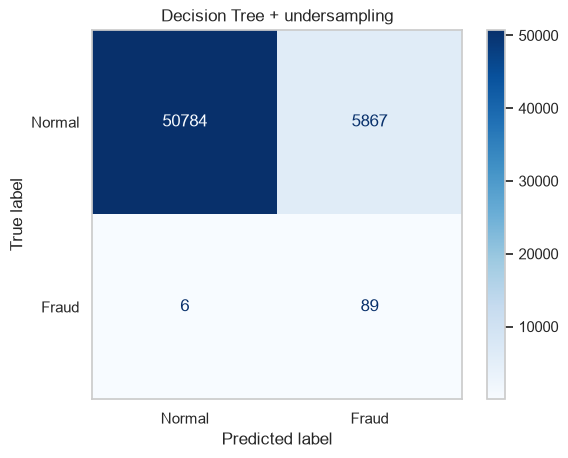

In [26]:
dt_under = train_and_evaluate(
    "Decision Tree + undersampling",
    Pipeline([("sampler", RandomUnderSampler(random_state=RANDOM_STATE)), ("model", make_dt())]),
)

Training time: 0.1 s
=== Random Forest + undersampling ===
              precision    recall  f1-score   support

      Normal     0.9998    0.9842    0.9919     56651
       Fraud     0.0848    0.8737    0.1546        95

    accuracy                         0.9840     56746
   macro avg     0.5423    0.9289    0.5732     56746
weighted avg     0.9983    0.9840    0.9905     56746



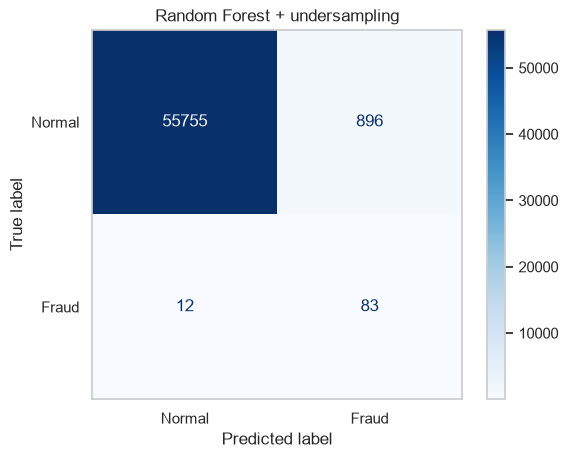

In [27]:
rf_under = train_and_evaluate(
    "Random Forest + undersampling",
    Pipeline([("sampler", RandomUnderSampler(random_state=RANDOM_STATE)), ("model", make_rf())]),
)

### 6.3 SMOTE oversampling

In [28]:
smote = SMOTE(random_state=RANDOM_STATE)
X_sm, y_sm = smote.fit_resample(X_train, y_train)
print("Training set after SMOTE:", X_sm.shape, dict(y_sm.value_counts()))

Training set after SMOTE: (453204, 30) {0: np.int64(226602), 1: np.int64(226602)}


Training time: 20.2 s
=== Decision Tree + SMOTE ===
              precision    recall  f1-score   support

      Normal     0.9995    0.9982    0.9988     56651
       Fraud     0.3882    0.6947    0.4981        95

    accuracy                         0.9977     56746
   macro avg     0.6939    0.8465    0.7485     56746
weighted avg     0.9985    0.9977    0.9980     56746



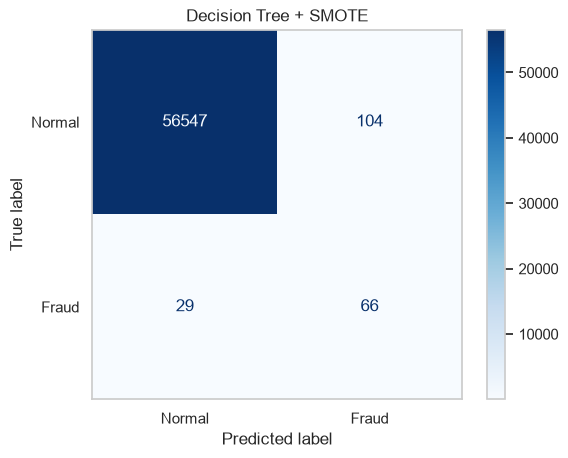

In [29]:
dt_smote = train_and_evaluate(
    "Decision Tree + SMOTE",
    Pipeline([("sampler", SMOTE(random_state=RANDOM_STATE)), ("model", make_dt())]),
)

Training time: 10.9 s
=== Random Forest + SMOTE ===
              precision    recall  f1-score   support

      Normal     0.9996    0.9999    0.9998     56651
       Fraud     0.9136    0.7789    0.8409        95

    accuracy                         0.9995     56746
   macro avg     0.9566    0.8894    0.9203     56746
weighted avg     0.9995    0.9995    0.9995     56746



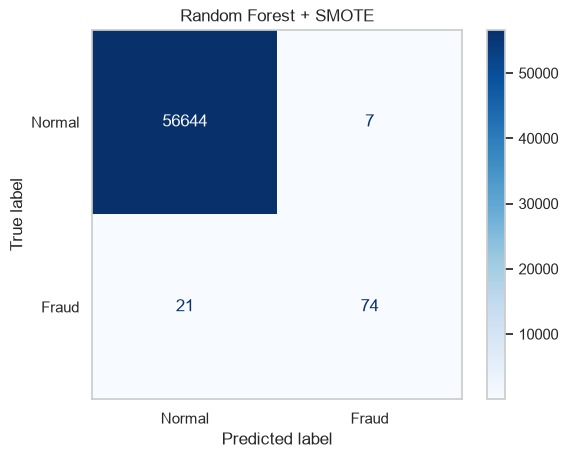

In [30]:
rf_smote = train_and_evaluate(
    "Random Forest + SMOTE",
    Pipeline([("sampler", SMOTE(random_state=RANDOM_STATE)), ("model", make_rf())]),
)

### 6.4 Comparison of all techniques

In [31]:
results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df.sort_values("PR-AUC", ascending=False)

,Accuracy,Precision,Recall,F1,PR-AUC,ROC-AUC,Train time (s)
Model,,,,,,,
Random Forest + SMOTE,0.9995,0.9136,0.7789,0.8409,0.8073,0.9590,10.9359
Random Forest + class weights,0.9995,0.9452,0.7263,0.8214,0.8012,0.9391,2.5110
Random Forest (baseline),0.9995,0.9718,0.7263,0.8313,0.7876,0.9239,6.2227
Random Forest + undersampling,0.9840,0.0848,0.8737,0.1546,0.6983,0.9767,0.1465
Decision Tree (baseline),0.9990,0.7204,0.7053,0.7128,0.5086,0.8524,7.8860
Decision Tree + class weights,0.9990,0.7349,0.6421,0.6854,0.4725,0.8209,3.3680
Decision Tree + SMOTE,0.9977,0.3882,0.6947,0.4981,0.2702,0.8465,20.2306
Decision Tree + undersampling,0.8965,0.0149,0.9368,0.0294,0.0141,0.9166,0.0254


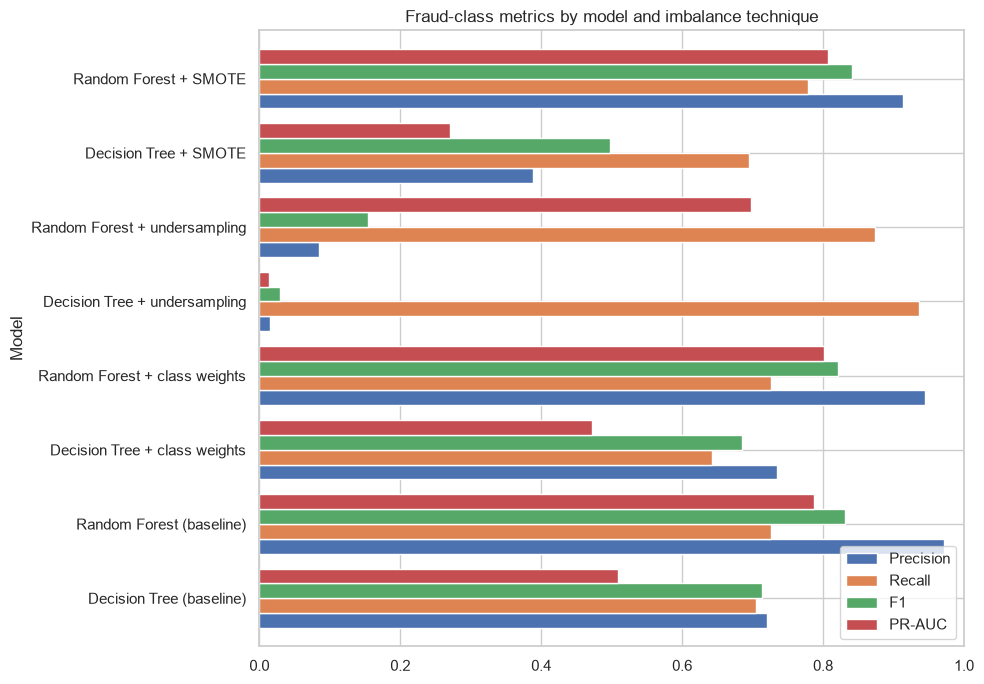

In [32]:
metrics = ["Precision", "Recall", "F1", "PR-AUC"]
ax = results_df[metrics].plot(kind="barh", figsize=(10, 7), width=0.8)
ax.set_xlim(0, 1)
ax.set_title("Fraud-class metrics by model and imbalance technique")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Observations

- **Random Forest + SMOTE** is the best overall: highest PR-AUC (0.807) and F1 (0.841), and recall rises from 0.726 to 0.779 while precision stays above 0.91.
- **Random Forest + class weights** is close behind (PR-AUC 0.801) and trains much faster, since no extra data is created.
- **Undersampling** gives the highest recall (0.874 for RF, 0.937 for DT) but precision collapses (8.5% and 1.5%): the models train on only 756 rows and flag far too many normal transactions as fraud.
- A single **Decision Tree** does not benefit from these techniques; with SMOTE its precision drops to 0.39. Trees overfit the synthetic or reweighted samples, while the Random Forest averages that out.
- There is a clear **precision/recall trade-off**. Step 7 (hyperparameter tuning) and Step 8 (threshold tuning) aim to improve recall without losing much precision.

## Step 7: Hyperparameter Tuning

We tune both models with `RandomizedSearchCV`:
- **3-fold `StratifiedKFold`** cross-validation on the training set only (the test set stays unseen).
- **Scoring = `average_precision`** (PR-AUC), the best metric for imbalanced data.
- **Decision Tree**: we also let the search choose between no weighting and `class_weight="balanced"`.
- **Random Forest + SMOTE**: the best combination from Step 6. SMOTE runs inside the pipeline, so it is re-applied to each training fold and never touches the validation fold. We also tune SMOTE's `sampling_strategy` (target fraud:normal ratio).

In [33]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import randint

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

### 7.1 Tuning the Decision Tree

In [34]:
dt_param_dist = {
    "criterion": ["gini", "entropy"],
    "max_depth": [4, 6, 8, 10, 12, 16, 20, None],
    "min_samples_split": randint(2, 50),
    "min_samples_leaf": randint(1, 30),
    "class_weight": [None, "balanced"],
}

dt_search = RandomizedSearchCV(
    make_dt(), dt_param_dist, n_iter=40, scoring="average_precision",
    cv=cv, n_jobs=-1, random_state=RANDOM_STATE, verbose=1,
)

start = time.time()
dt_search.fit(X_train, y_train)
print(f"Search time: {time.time() - start:.0f} s")
print("Best params:", dt_search.best_params_)
print(f"Best CV PR-AUC: {dt_search.best_score_:.4f}")

Fitting 3 folds for each of 40 candidates, totalling 120 fits
Search time: 53 s
Best params: {'class_weight': None, 'criterion': 'gini', 'max_depth': 20, 'min_samples_leaf': 21, 'min_samples_split': 10}
Best CV PR-AUC: 0.7744


=== Decision Tree (tuned) ===
              precision    recall  f1-score   support

      Normal     0.9995    0.9998    0.9996     56651
       Fraud     0.8553    0.6842    0.7602        95

    accuracy                         0.9993     56746
   macro avg     0.9274    0.8420    0.8799     56746
weighted avg     0.9992    0.9993    0.9992     56746



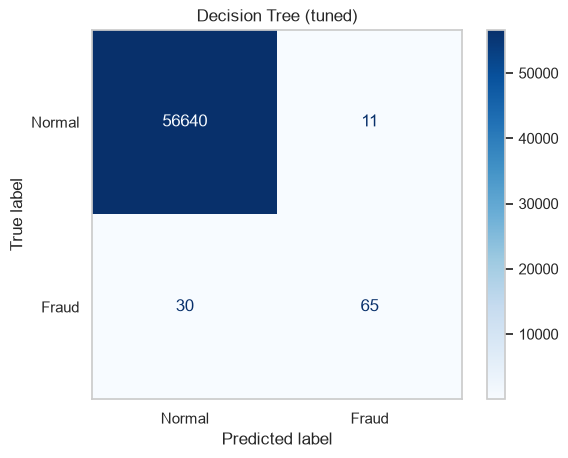

In [35]:
dt_tuned = dt_search.best_estimator_
evaluate("Decision Tree (tuned)", dt_tuned, X_test, y_test, dt_search.refit_time_);

### 7.2 Tuning the Random Forest + SMOTE

This is the slowest step. Each forest uses one core (`n_jobs=1`) while the search runs many fits in parallel (`n_jobs=-1`), which is faster than parallelising inside each forest.

In [36]:
rf_pipe = Pipeline([
    ("sampler", SMOTE(random_state=RANDOM_STATE)),
    ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)),
])

rf_param_dist = {
    "sampler__sampling_strategy": [0.1, 0.25, 0.5, 1.0],
    "sampler__k_neighbors": [3, 5, 7],
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [10, 15, 20, None],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2", 0.3],
}

rf_search = RandomizedSearchCV(
    rf_pipe, rf_param_dist, n_iter=20, scoring="average_precision",
    cv=cv, n_jobs=-1, random_state=RANDOM_STATE, verbose=1,
)

start = time.time()
rf_search.fit(X_train, y_train)
print(f"Search time: {time.time() - start:.0f} s")
print("Best params:", rf_search.best_params_)
print(f"Best CV PR-AUC: {rf_search.best_score_:.4f}")

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Search time: 1051 s
Best params: {'sampler__sampling_strategy': 0.1, 'sampler__k_neighbors': 5, 'model__n_estimators': 200, 'model__min_samples_leaf': 4, 'model__max_features': 'sqrt', 'model__max_depth': 20}
Best CV PR-AUC: 0.8473


=== Random Forest + SMOTE (tuned) ===
              precision    recall  f1-score   support

      Normal     0.9996    0.9999    0.9997     56651
       Fraud     0.9231    0.7579    0.8324        95

    accuracy                         0.9995     56746
   macro avg     0.9613    0.8789    0.9161     56746
weighted avg     0.9995    0.9995    0.9995     56746



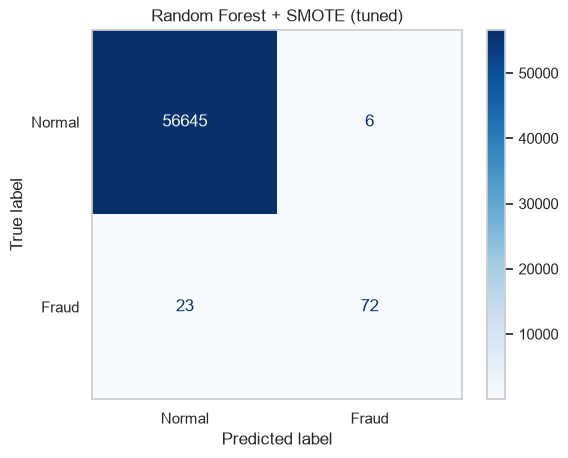

In [37]:
rf_tuned = rf_search.best_estimator_
evaluate("Random Forest + SMOTE (tuned)", rf_tuned, X_test, y_test, rf_search.refit_time_);

### 7.3 Top search results

In [38]:
def top_results(search, n=5):
    cols = ["mean_test_score", "std_test_score", "params"]
    return pd.DataFrame(search.cv_results_)[cols].sort_values("mean_test_score", ascending=False).head(n)


display(top_results(dt_search))
display(top_results(rf_search))

,mean_test_score,std_test_score,params
10,0.774350,0.033958,"{'class_weight': None, 'criterion': 'gini', 'm..."
39,0.770404,0.027713,"{'class_weight': None, 'criterion': 'entropy',..."
9,0.768873,0.025409,"{'class_weight': None, 'criterion': 'entropy',..."
11,0.768670,0.024366,"{'class_weight': None, 'criterion': 'entropy',..."
2,0.766209,0.038573,"{'class_weight': None, 'criterion': 'gini', 'm..."


,mean_test_score,std_test_score,params
10,0.847263,0.023115,"{'sampler__sampling_strategy': 0.1, 'sampler__..."
12,0.845748,0.022656,"{'sampler__sampling_strategy': 0.1, 'sampler__..."
18,0.845639,0.018874,"{'sampler__sampling_strategy': 0.25, 'sampler_..."
2,0.844084,0.023409,"{'sampler__sampling_strategy': 0.25, 'sampler_..."
3,0.843577,0.015644,"{'sampler__sampling_strategy': 0.25, 'sampler_..."


In [39]:
results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df.sort_values("PR-AUC", ascending=False)

,Accuracy,Precision,Recall,F1,PR-AUC,ROC-AUC,Train time (s)
Model,,,,,,,
Random Forest + SMOTE (tuned),0.9995,0.9231,0.7579,0.8324,0.8238,0.9749,140.8998
Random Forest + SMOTE,0.9995,0.9136,0.7789,0.8409,0.8073,0.9590,10.9359
Random Forest + class weights,0.9995,0.9452,0.7263,0.8214,0.8012,0.9391,2.5110
Random Forest (baseline),0.9995,0.9718,0.7263,0.8313,0.7876,0.9239,6.2227
Decision Tree (tuned),0.9993,0.8553,0.6842,0.7602,0.7090,0.8858,13.5795
Random Forest + undersampling,0.9840,0.0848,0.8737,0.1546,0.6983,0.9767,0.1465
Decision Tree (baseline),0.9990,0.7204,0.7053,0.7128,0.5086,0.8524,7.8860
Decision Tree + class weights,0.9990,0.7349,0.6421,0.6854,0.4725,0.8209,3.3680
Decision Tree + SMOTE,0.9977,0.3882,0.6947,0.4981,0.2702,0.8465,20.2306


### Observations

- Tuning helped the **Decision Tree** most: PR-AUC 0.51 → 0.71 and precision 0.72 → 0.86. Limiting depth (`max_depth=20`) and leaf size (`min_samples_leaf=21`) stops it from overfitting.
- The **tuned Random Forest + SMOTE** has the best PR-AUC (0.824) and ROC-AUC (0.975) of all models, so it ranks frauds best.
- The search preferred light oversampling (`sampling_strategy=0.1`) over fully balancing the classes.
- Its recall at the default 0.5 threshold (0.758) is slightly below the untuned model; Step 8 tunes the threshold to fix this.
- CV PR-AUC (0.847) and test PR-AUC (0.824) are close, so the model is not overfitting the search.

## Step 8: Threshold Tuning

By default a model predicts fraud when its probability is ≥ 0.5. On imbalanced data a different threshold usually gives a better precision/recall balance.

To avoid tuning on the test set, we choose the threshold from **out-of-fold probabilities on the training set** (`cross_val_predict`), then apply it once to the test set.

Two thresholds are compared:
- **Best F1**: the best balance of precision and recall.
- **Recall ≥ 85%**: the highest threshold that still catches at least 85% of frauds (in a bank, missing fraud is usually costlier than a false alarm).

In [40]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, PrecisionRecallDisplay


class ThresholdModel:
    """Wrap a fitted model so predict() uses a custom probability threshold."""

    def __init__(self, model, threshold):
        self.model = model
        self.threshold = threshold

    def predict_proba(self, X):
        return self.model.predict_proba(X)

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= self.threshold).astype(int)


def oof_probabilities(model):
    """Out-of-fold fraud probabilities on the training set (same CV as Step 7)."""
    return cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]


def choose_thresholds(y_true, y_prob, min_recall=0.85):
    precision, recall, thresholds = precision_recall_curve(y_true, y_prob)
    precision, recall = precision[:-1], recall[:-1]  # last point has no threshold
    f1 = 2 * precision * recall / (precision + recall + 1e-12)

    best_f1 = thresholds[np.argmax(f1)]
    ok = recall >= min_recall
    high_recall = thresholds[ok].max() if ok.any() else thresholds.min()
    return best_f1, high_recall, (precision, recall, thresholds, f1)

### 8.1 Out-of-fold probabilities

The Random Forest is re-created with `n_jobs=-1` so each fit uses all cores (about 1–2 minutes in total).

In [41]:
dt_for_cv = clone(dt_tuned)
rf_for_cv = clone(rf_tuned).set_params(model__n_jobs=-1)

start = time.time()
dt_oof = oof_probabilities(dt_for_cv)
rf_oof = oof_probabilities(rf_for_cv)
print(f"Done in {time.time() - start:.0f} s")

dt_thr_f1, dt_thr_rec, dt_curve = choose_thresholds(y_train, dt_oof)
rf_thr_f1, rf_thr_rec, rf_curve = choose_thresholds(y_train, rf_oof)

print(f"Decision Tree  -> best-F1 threshold: {dt_thr_f1:.3f}, recall>=85% threshold: {dt_thr_rec:.3f}")
print(f"Random Forest  -> best-F1 threshold: {rf_thr_f1:.3f}, recall>=85% threshold: {rf_thr_rec:.3f}")

Done in 30 s
Decision Tree  -> best-F1 threshold: 0.438, recall>=85% threshold: 0.000
Random Forest  -> best-F1 threshold: 0.643, recall>=85% threshold: 0.252


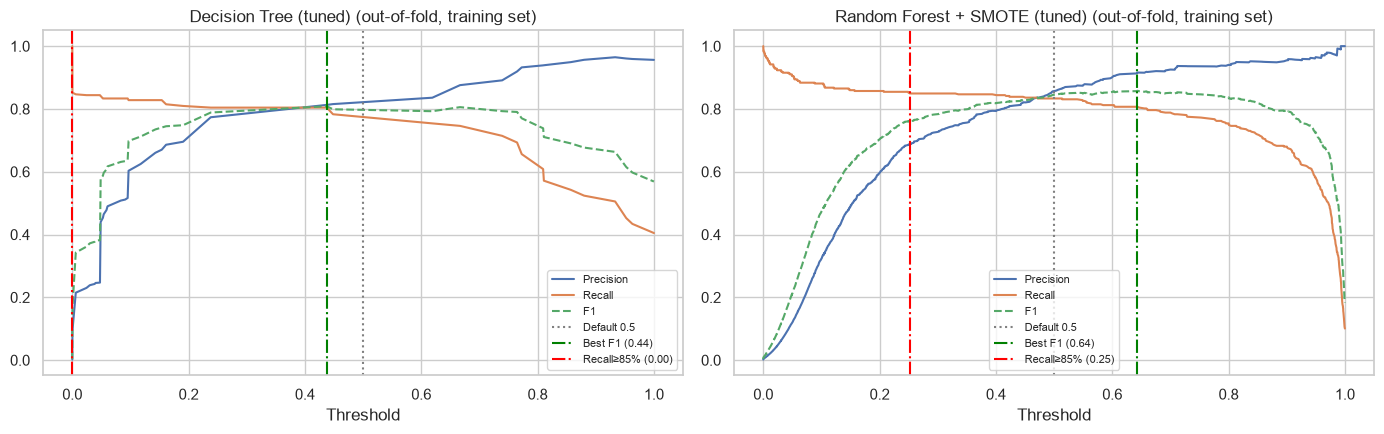

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (name, curve, t_f1, t_rec) in zip(axes, [
    ("Decision Tree (tuned)", dt_curve, dt_thr_f1, dt_thr_rec),
    ("Random Forest + SMOTE (tuned)", rf_curve, rf_thr_f1, rf_thr_rec),
]):
    precision, recall, thresholds, f1 = curve
    ax.plot(thresholds, precision, label="Precision")
    ax.plot(thresholds, recall, label="Recall")
    ax.plot(thresholds, f1, label="F1", linestyle="--")
    ax.axvline(0.5, color="grey", linestyle=":", label="Default 0.5")
    ax.axvline(t_f1, color="green", linestyle="-.", label=f"Best F1 ({t_f1:.2f})")
    ax.axvline(t_rec, color="red", linestyle="-.", label=f"Recall≥85% ({t_rec:.2f})")
    ax.set_xlabel("Threshold")
    ax.set_title(f"{name} (out-of-fold, training set)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 8.2 Apply the thresholds to the test set

=== Decision Tree (tuned, thr=0.44, best F1) ===
              precision    recall  f1-score   support

      Normal     0.9995    0.9998    0.9996     56651
       Fraud     0.8553    0.6842    0.7602        95

    accuracy                         0.9993     56746
   macro avg     0.9274    0.8420    0.8799     56746
weighted avg     0.9992    0.9993    0.9992     56746



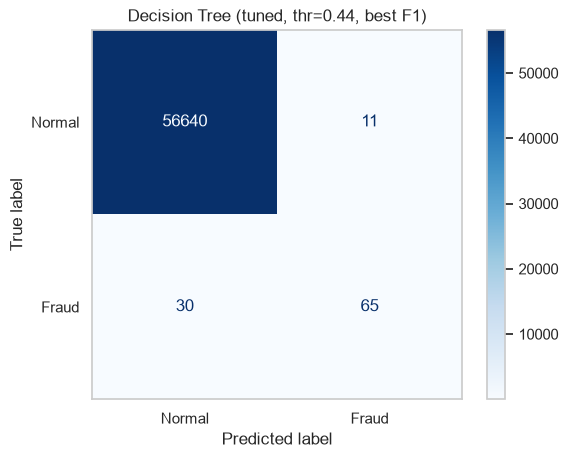

=== Decision Tree (tuned, thr=0.00, recall≥85%) ===
              precision    recall  f1-score   support

      Normal     0.9996    0.9678    0.9834     56651
       Fraud     0.0390    0.7789    0.0742        95

    accuracy                         0.9675     56746
   macro avg     0.5193    0.8734    0.5288     56746
weighted avg     0.9980    0.9675    0.9819     56746



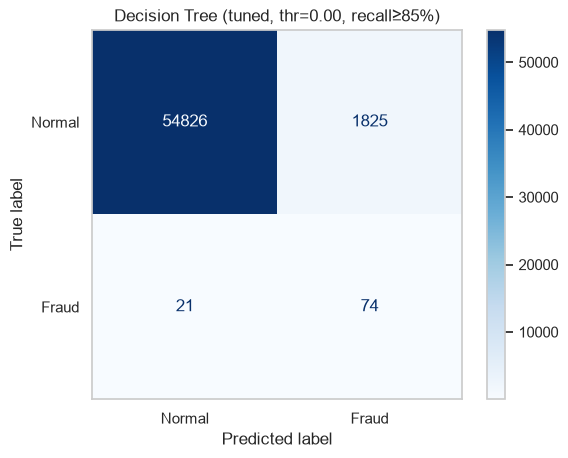

In [43]:
evaluate(f"Decision Tree (tuned, thr={dt_thr_f1:.2f}, best F1)", ThresholdModel(dt_tuned, dt_thr_f1), X_test, y_test)
evaluate(f"Decision Tree (tuned, thr={dt_thr_rec:.2f}, recall≥85%)", ThresholdModel(dt_tuned, dt_thr_rec), X_test, y_test);

=== Random Forest + SMOTE (tuned, thr=0.64, best F1) ===
              precision    recall  f1-score   support

      Normal     0.9996    0.9999    0.9997     56651
       Fraud     0.9459    0.7368    0.8284        95

    accuracy                         0.9995     56746
   macro avg     0.9728    0.8684    0.9141     56746
weighted avg     0.9995    0.9995    0.9995     56746



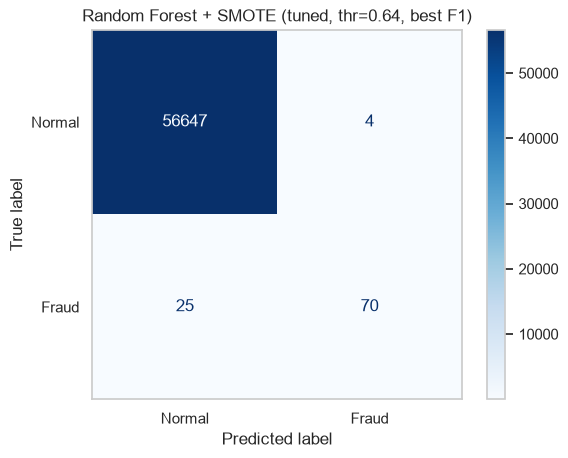

=== Random Forest + SMOTE (tuned, thr=0.25, recall≥85%) ===
              precision    recall  f1-score   support

      Normal     0.9997    0.9995    0.9996     56651
       Fraud     0.7222    0.8211    0.7685        95

    accuracy                         0.9992     56746
   macro avg     0.8610    0.9103    0.8840     56746
weighted avg     0.9992    0.9992    0.9992     56746



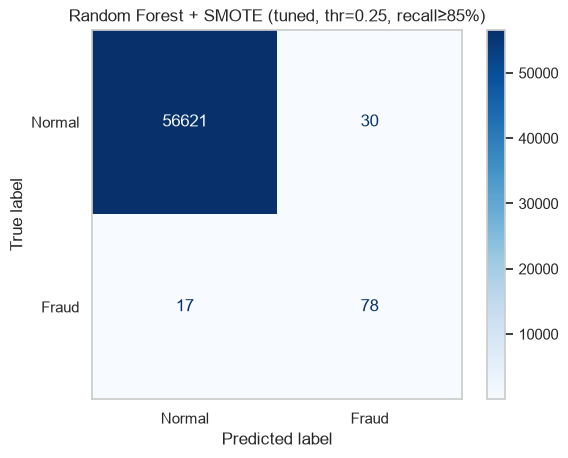

In [44]:
evaluate(f"Random Forest + SMOTE (tuned, thr={rf_thr_f1:.2f}, best F1)", ThresholdModel(rf_tuned, rf_thr_f1), X_test, y_test)
evaluate(f"Random Forest + SMOTE (tuned, thr={rf_thr_rec:.2f}, recall≥85%)", ThresholdModel(rf_tuned, rf_thr_rec), X_test, y_test);

### 8.3 Precision-recall curves on the test set

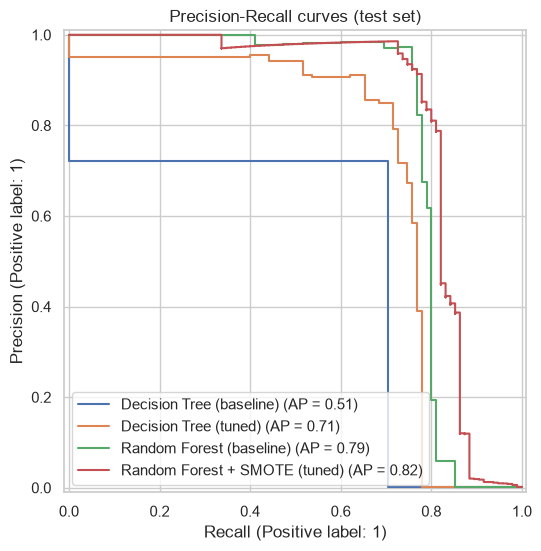

In [45]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, model in [
    ("Decision Tree (baseline)", dt_base),
    ("Decision Tree (tuned)", dt_tuned),
    ("Random Forest (baseline)", rf_base),
    ("Random Forest + SMOTE (tuned)", rf_tuned),
]:
    PrecisionRecallDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.set_title("Precision-Recall curves (test set)")
plt.show()

In [46]:
results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df.sort_values("F1", ascending=False)

,Accuracy,Precision,Recall,F1,PR-AUC,ROC-AUC,Train time (s)
Model,,,,,,,
Random Forest + SMOTE,0.9995,0.9136,0.7789,0.8409,0.8073,0.9590,10.9359
Random Forest + SMOTE (tuned),0.9995,0.9231,0.7579,0.8324,0.8238,0.9749,140.8998
Random Forest (baseline),0.9995,0.9718,0.7263,0.8313,0.7876,0.9239,6.2227
"Random Forest + SMOTE (tuned, thr=0.64, best F1)",0.9995,0.9459,0.7368,0.8284,0.8238,0.9749,NaN
Random Forest + class weights,0.9995,0.9452,0.7263,0.8214,0.8012,0.9391,2.5110
"Random Forest + SMOTE (tuned, thr=0.25, recall≥85%)",0.9992,0.7222,0.8211,0.7685,0.8238,0.9749,NaN
"Decision Tree (tuned, thr=0.44, best F1)",0.9993,0.8553,0.6842,0.7602,0.7090,0.8858,NaN
Decision Tree (tuned),0.9993,0.8553,0.6842,0.7602,0.7090,0.8858,13.5795
Decision Tree (baseline),0.9990,0.7204,0.7053,0.7128,0.5086,0.8524,7.8860


### Observations

- **Random Forest + SMOTE (tuned) at threshold 0.25** catches 78 of 95 frauds (recall 0.821), up from 72 at the default 0.5. The cost is about 24 extra false alarms out of 56,651 normal transactions (≈0.05%), a good trade-off for fraud detection.
- The **best-F1 threshold (0.64)** gives slightly higher precision (0.946) but F1 is almost unchanged (0.828 vs 0.832), so the default threshold was already close to optimal for F1. With only 95 test frauds, a difference of 1–2 cases is within noise.
- The **Decision Tree cannot use a recall ≥ 85% threshold**: a single tree outputs only a few distinct probabilities (one per leaf), so the threshold drops to ≈0, and precision collapses to 3.9%. The row is kept in the table to show this limitation; the Random Forest's averaged, smoother probabilities are what make threshold tuning useful.
- Even at a low threshold some frauds are still missed; no threshold catches every fraud without a flood of false alarms.

## Step 9: Feature Importance, Final Comparison and Conclusion

### 9.1 Feature importance

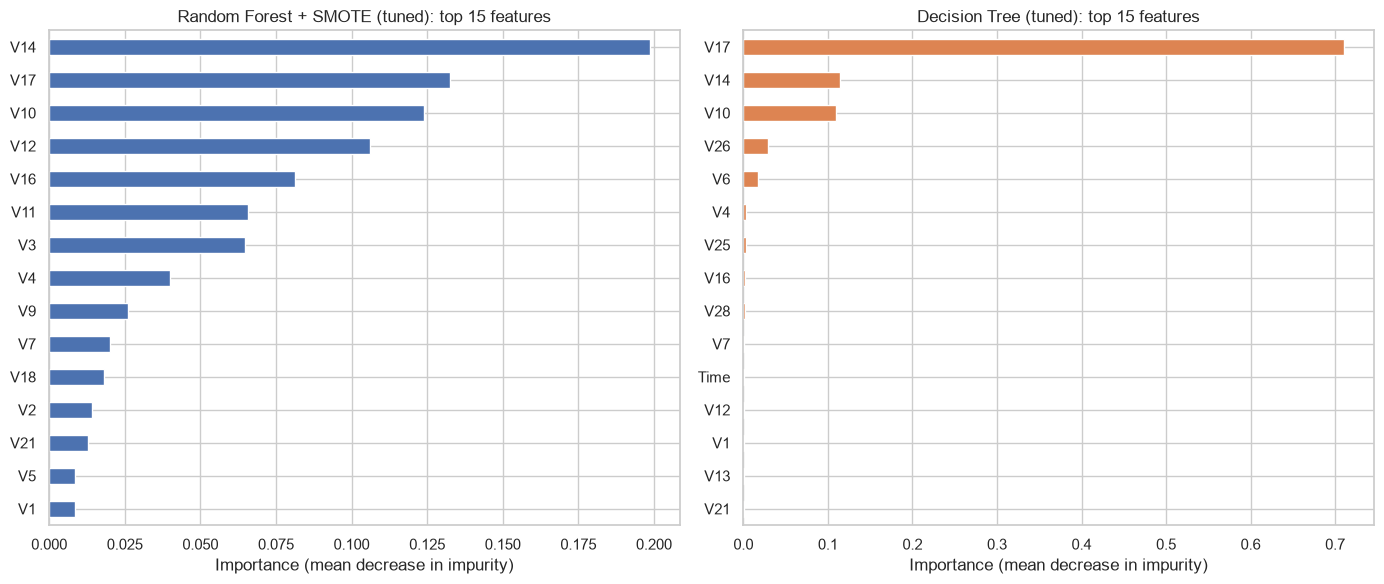

,Random Forest,Decision Tree
V14,0.1986,0.1140
V17,0.1327,0.7105
V10,0.1241,0.1098
V12,0.1062,0.0010
V16,0.0813,0.0019
V11,0.0659,0.0003
V3,0.0646,0.0006
V4,0.0401,0.0032
V9,0.0261,0.0000
V7,0.0200,0.0013


In [47]:
rf_importance = pd.Series(rf_tuned.named_steps["model"].feature_importances_, index=X_train.columns)
dt_importance = pd.Series(dt_tuned.feature_importances_, index=X_train.columns)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
rf_importance.sort_values().tail(15).plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set_title("Random Forest + SMOTE (tuned): top 15 features")
dt_importance.sort_values().tail(15).plot(kind="barh", ax=axes[1], color="#DD8452")
axes[1].set_title("Decision Tree (tuned): top 15 features")
for ax in axes:
    ax.set_xlabel("Importance (mean decrease in impurity)")
plt.tight_layout()
plt.show()

importance_df = pd.DataFrame({"Random Forest": rf_importance, "Decision Tree": dt_importance})
importance_df.sort_values("Random Forest", ascending=False).head(10).round(4)

In [48]:
# Compare with the features most correlated with Class in Step 2
top_rf = rf_importance.sort_values(ascending=False).head(6).index.tolist()
print("Top 6 by Random Forest importance:", top_rf)
print("Top 6 by correlation (Step 2):     ", top_features)
print("In both:", sorted(set(top_rf) & set(top_features)))

Top 6 by Random Forest importance: ['V14', 'V17', 'V10', 'V12', 'V16', 'V11']
Top 6 by correlation (Step 2):      ['V17', 'V14', 'V12', 'V10', 'V16', 'V3']
In both: ['V10', 'V12', 'V14', 'V16', 'V17']


### 9.2 Final comparison

One row per approach, from baseline to the final tuned models.

In [49]:
final_models = [
    "Decision Tree (baseline)",
    "Decision Tree (tuned)",
    "Random Forest (baseline)",
    "Random Forest + class weights",
    "Random Forest + SMOTE",
    "Random Forest + SMOTE (tuned)",
    f"Random Forest + SMOTE (tuned, thr={rf_thr_f1:.2f}, best F1)",
    f"Random Forest + SMOTE (tuned, thr={rf_thr_rec:.2f}, recall≥85%)",
]
results_df = pd.DataFrame(results).set_index("Model")
final_df = results_df.loc[final_models, ["Precision", "Recall", "F1", "PR-AUC", "ROC-AUC"]].round(4)
final_df

,Precision,Recall,F1,PR-AUC,ROC-AUC
Model,,,,,
Decision Tree (baseline),0.7204,0.7053,0.7128,0.5086,0.8524
Decision Tree (tuned),0.8553,0.6842,0.7602,0.7090,0.8858
Random Forest (baseline),0.9718,0.7263,0.8313,0.7876,0.9239
Random Forest + class weights,0.9452,0.7263,0.8214,0.8012,0.9391
Random Forest + SMOTE,0.9136,0.7789,0.8409,0.8073,0.9590
Random Forest + SMOTE (tuned),0.9231,0.7579,0.8324,0.8238,0.9749
"Random Forest + SMOTE (tuned, thr=0.64, best F1)",0.9459,0.7368,0.8284,0.8238,0.9749
"Random Forest + SMOTE (tuned, thr=0.25, recall≥85%)",0.7222,0.8211,0.7685,0.8238,0.9749


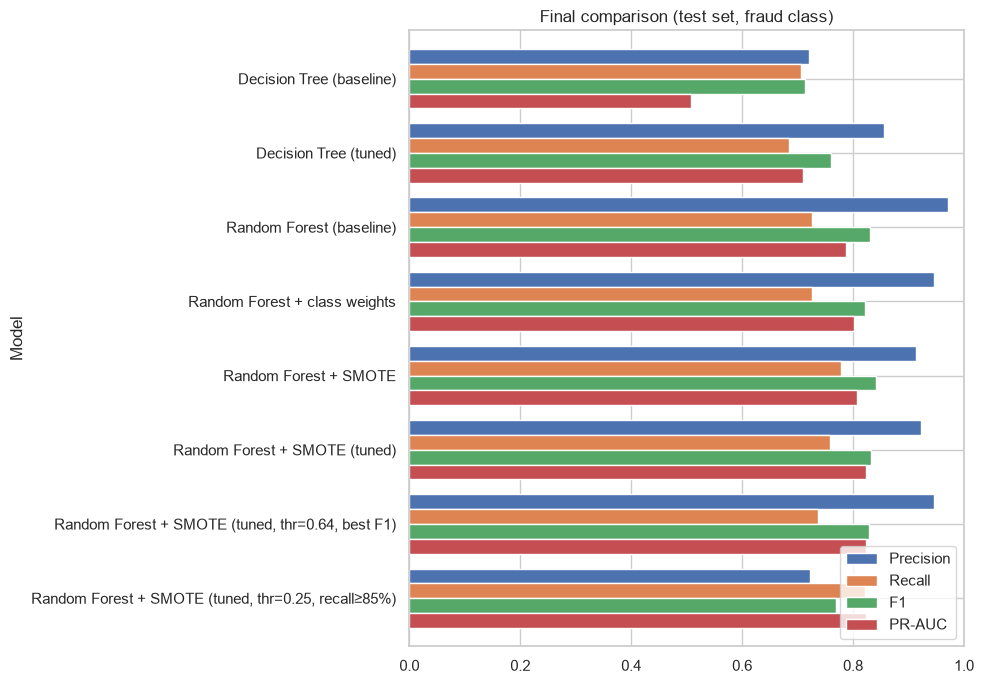

In [50]:
ax = final_df[["Precision", "Recall", "F1", "PR-AUC"]].plot(kind="barh", figsize=(10, 7), width=0.8)
ax.set_xlim(0, 1)
ax.invert_yaxis()
ax.set_title("Final comparison (test set, fraud class)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

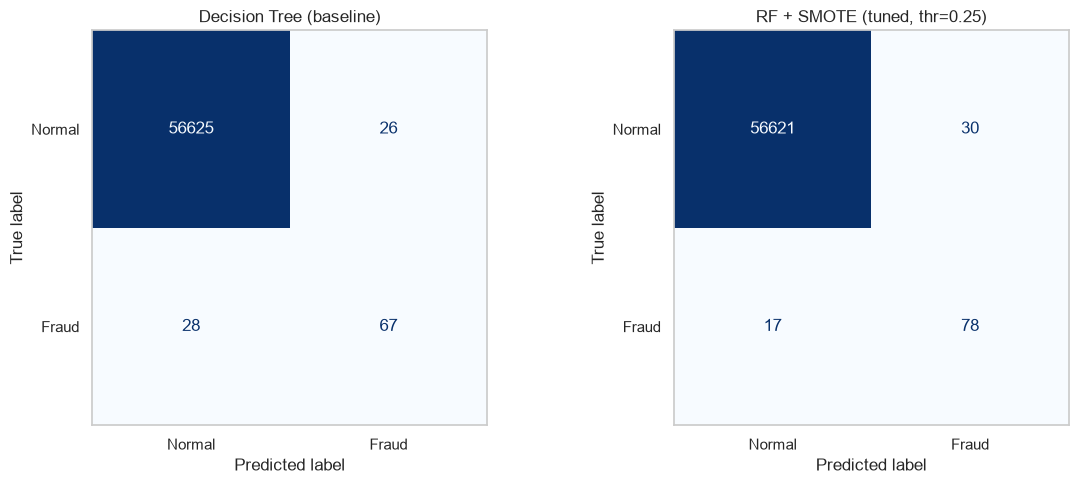

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, model) in zip(axes, [
    ("Decision Tree (baseline)", dt_base),
    (f"RF + SMOTE (tuned, thr={rf_thr_rec:.2f})", ThresholdModel(rf_tuned, rf_thr_rec)),
]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, model.predict(X_test)), display_labels=["Normal", "Fraud"]).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
plt.show()

### 9.3 Conclusion (Decision Tree vs Random Forest)

*See the **Final Conclusion** at the end for the comparison with all models.*

- **Accuracy is misleading** on this dataset (~0.17% fraud): every model scores ≈99.9%. Precision, recall, F1 and especially **PR-AUC** are the right metrics.
- The **Random Forest outperforms the Decision Tree** in every setting. Averaging many trees reduces overfitting and gives smoother probabilities (baseline PR-AUC 0.79 vs 0.51).
- **Imbalance handling helps the Random Forest but not the single Decision Tree.** SMOTE and class weights improved the forest; undersampling raised recall but destroyed precision because only 756 training rows were left.
- **Hyperparameter tuning** gave the biggest gain for the Decision Tree (PR-AUC 0.51 → 0.71) and produced the best overall model: **Random Forest + light SMOTE (ratio 0.1), 200 trees, max depth 20**, with test PR-AUC 0.824 and ROC-AUC 0.975.
- **Threshold tuning** lets the bank choose its trade-off. At threshold 0.25 the final model catches **82% of frauds (78/95) with 72% precision**; at 0.64 it reaches 95% precision with 74% recall.
- The Random Forest's most important features (`V14`, `V17`, `V10`, `V12`, `V16`) are 5 of the 6 features most correlated with fraud in the EDA. The tuned Decision Tree relies on `V17` alone for 71% of its importance, while the forest spreads importance across many features, one reason it generalises better.

**Limitations and future work:** the test set has only 95 frauds, so small metric differences are not significant; features are anonymised PCA components, so results are hard to interpret in business terms; boosting models (XGBoost/LightGBM, which can also use the GPU) and cost-sensitive evaluation are natural next steps.

## Step 10: More Models — Logistic Regression, XGBoost and LightGBM

We compare the tree models with three more approaches:

| Model | Type | Imbalance handling |
|---|---|---|
| **Logistic Regression** | Linear baseline | `class_weight="balanced"` |
| **XGBoost** | Gradient boosting (on the **GPU**) | `scale_pos_weight` |
| **LightGBM** | Gradient boosting (CPU) | `scale_pos_weight` |

This gives the full picture: **linear → single tree → bagging (Random Forest) → boosting (XGBoost, LightGBM)**.

Both boosting models get a quick `RandomizedSearchCV` (same 3-fold CV and PR-AUC scoring as Step 7) and threshold tuning (same method as Step 8).

In [52]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from scipy.stats import uniform, loguniform
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# scale_pos_weight = (#normal / #fraud) in the training set: same idea as class weights
POS_WEIGHT = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {POS_WEIGHT:.1f}")

# Use the GPU for XGBoost if it works, otherwise fall back to the CPU
try:
    XGBClassifier(device="cuda", n_estimators=1).fit(X_train.head(1000), y_train.head(1000))
    XGB_DEVICE = "cuda"
except Exception as e:
    print("GPU not available for XGBoost:", e)
    XGB_DEVICE = "cpu"
print("XGBoost device:", XGB_DEVICE)

scale_pos_weight = 599.5
XGBoost device: cuda


### 10.1 Logistic Regression

A linear model needs all features on the same scale, so `StandardScaler` is added in front of it.

Training time: 0.9 s
=== Logistic Regression (balanced) ===
              precision    recall  f1-score   support

      Normal     0.9998    0.9755    0.9875     56651
       Fraud     0.0564    0.8737    0.1059        95

    accuracy                         0.9753     56746
   macro avg     0.5281    0.9246    0.5467     56746
weighted avg     0.9982    0.9753    0.9860     56746



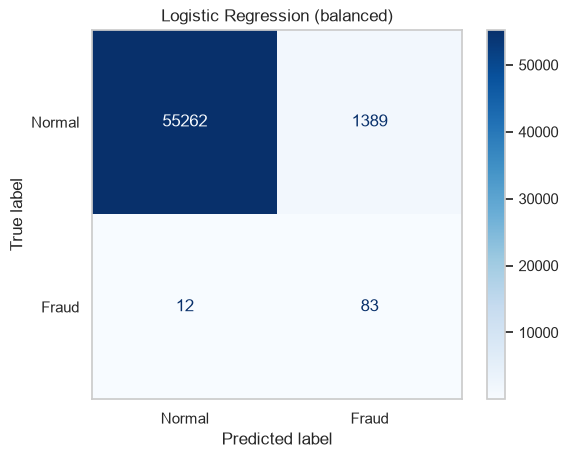

In [54]:
lr = train_and_evaluate(
    "Logistic Regression (balanced)",
    make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE)),
)

Training time: 0.3 s
=== Logistic Regression (no weighting) ===
              precision    recall  f1-score   support

      Normal     0.9993    0.9998    0.9996     56651
       Fraud     0.8462    0.5789    0.6875        95

    accuracy                         0.9991     56746
   macro avg     0.9227    0.7894    0.8435     56746
weighted avg     0.9990    0.9991    0.9990     56746



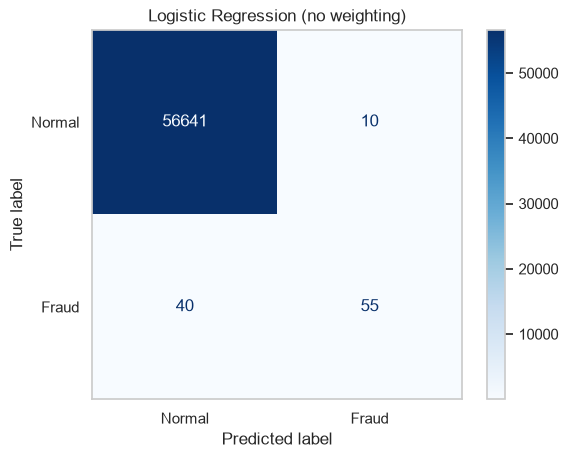

In [55]:
lr_plain = train_and_evaluate(
    "Logistic Regression (no weighting)",
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
)

### 10.2 XGBoost (GPU)

Training time: 1.3 s
=== XGBoost (baseline) ===
              precision    recall  f1-score   support

      Normal     0.9996    1.0000    0.9998     56651
       Fraud     0.9730    0.7579    0.8521        95

    accuracy                         0.9996     56746
   macro avg     0.9863    0.8789    0.9259     56746
weighted avg     0.9995    0.9996    0.9995     56746



/home/gaurav/Desktop/creditcard/.venv/lib/python3.12/site-packages/xgboost/core.py:569: UserWarning: [11:10:19] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


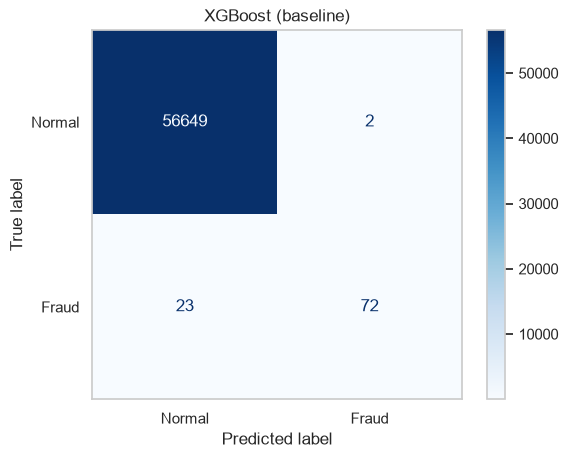

Training time: 1.3 s
=== XGBoost + scale_pos_weight ===
              precision    recall  f1-score   support

      Normal     0.9996    0.9999    0.9998     56651
       Fraud     0.9359    0.7684    0.8439        95

    accuracy                         0.9995     56746
   macro avg     0.9678    0.8842    0.9218     56746
weighted avg     0.9995    0.9995    0.9995     56746



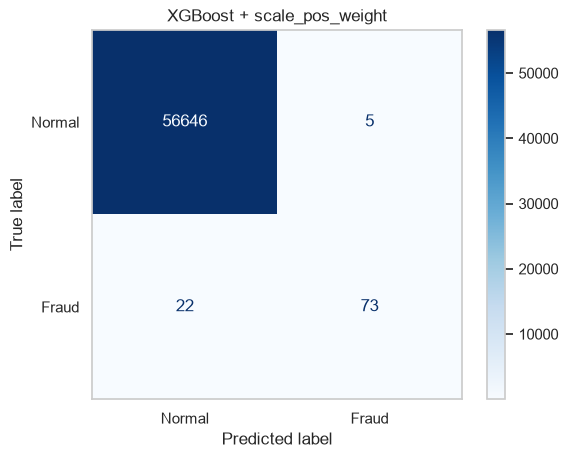

In [56]:
def make_xgb(**kwargs):
    params = dict(
        n_estimators=500, learning_rate=0.05, max_depth=6, tree_method="hist",
        device=XGB_DEVICE, eval_metric="aucpr", random_state=RANDOM_STATE,
    )
    params.update(kwargs)
    return XGBClassifier(**params)


xgb_base = train_and_evaluate("XGBoost (baseline)", make_xgb())
xgb_weighted = train_and_evaluate("XGBoost + scale_pos_weight", make_xgb(scale_pos_weight=POS_WEIGHT))

**Tuning XGBoost.** The search runs fits one at a time (`n_jobs=1`) because they all share the single GPU. `scale_pos_weight` is tuned too: the full ratio (~600) is often too strong, and a smaller value can give a better precision/recall balance.

Fitting 3 folds for each of 25 candidates, totalling 75 fits
Search time: 67 s
Best params: {'colsample_bytree': np.float64(0.8566223936114975), 'learning_rate': np.float64(0.09767966657678313), 'max_depth': 4, 'min_child_weight': 5, 'n_estimators': 800, 'scale_pos_weight': np.float64(599.4761904761905), 'subsample': np.float64(0.7975182385457563)}
Best CV PR-AUC: 0.8535
=== XGBoost (tuned) ===
              precision    recall  f1-score   support

      Normal     0.9996    0.9999    0.9998     56651
       Fraud     0.9494    0.7895    0.8621        95

    accuracy                         0.9996     56746
   macro avg     0.9745    0.8947    0.9309     56746
weighted avg     0.9996    0.9996    0.9996     56746



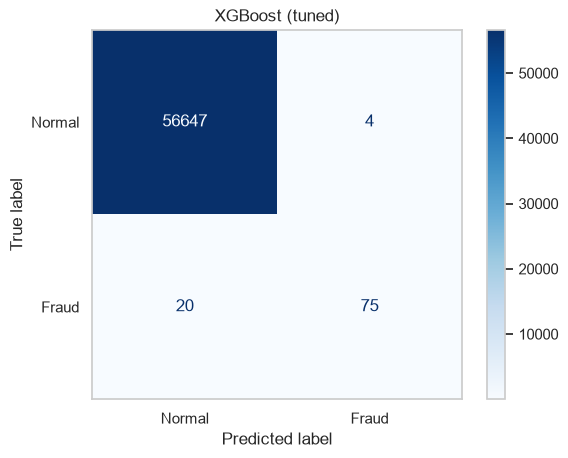

In [57]:
xgb_param_dist = {
    "n_estimators": [300, 500, 800],
    "learning_rate": loguniform(0.01, 0.2),
    "max_depth": [3, 4, 5, 6, 8],
    "min_child_weight": [1, 3, 5],
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.5, 0.5),
    "scale_pos_weight": [1, 5, 10, 25, 50, POS_WEIGHT],
}

xgb_search = RandomizedSearchCV(
    make_xgb(), xgb_param_dist, n_iter=25, scoring="average_precision",
    cv=cv, n_jobs=1, random_state=RANDOM_STATE, verbose=1,
)

start = time.time()
xgb_search.fit(X_train, y_train)
print(f"Search time: {time.time() - start:.0f} s")
print("Best params:", xgb_search.best_params_)
print(f"Best CV PR-AUC: {xgb_search.best_score_:.4f}")

xgb_tuned = xgb_search.best_estimator_
evaluate("XGBoost (tuned)", xgb_tuned, X_test, y_test, xgb_search.refit_time_);

### 10.3 LightGBM

Training time: 6.0 s
=== LightGBM (baseline) ===
              precision    recall  f1-score   support

      Normal     0.9994    0.9970    0.9982     56651
       Fraud     0.2597    0.6316    0.3681        95

    accuracy                         0.9964     56746
   macro avg     0.6296    0.8143    0.6831     56746
weighted avg     0.9981    0.9964    0.9971     56746



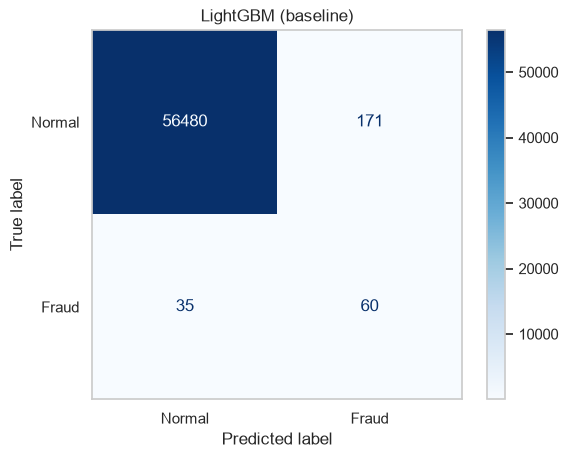

Training time: 2.2 s
=== LightGBM + scale_pos_weight ===
              precision    recall  f1-score   support

      Normal     0.9996    0.9354    0.9665     56651
       Fraud     0.0203    0.8000    0.0397        95

    accuracy                         0.9352     56746
   macro avg     0.5100    0.8677    0.5031     56746
weighted avg     0.9980    0.9352    0.9649     56746



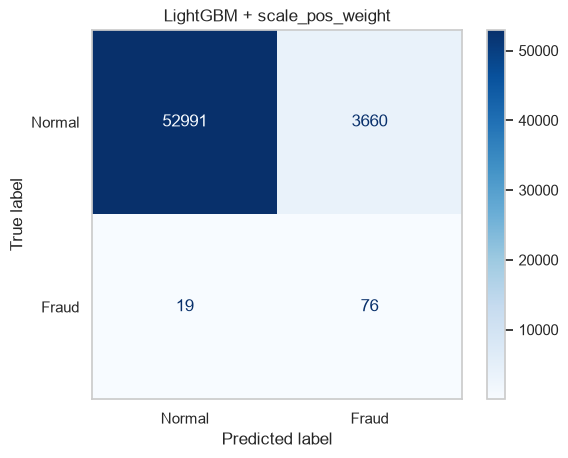

In [58]:
def make_lgbm(**kwargs):
    params = dict(n_estimators=500, learning_rate=0.05, num_leaves=31, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
    params.update(kwargs)
    return LGBMClassifier(**params)


lgbm_base = train_and_evaluate("LightGBM (baseline)", make_lgbm())
lgbm_weighted = train_and_evaluate("LightGBM + scale_pos_weight", make_lgbm(scale_pos_weight=POS_WEIGHT))

Fitting 3 folds for each of 25 candidates, totalling 75 fits
Search time: 60 s
Best params: {'colsample_bytree': np.float64(0.5993578407670862), 'learning_rate': np.float64(0.010166803740022877), 'min_child_samples': 50, 'n_estimators': 800, 'num_leaves': 15, 'reg_lambda': np.float64(0.7004349545230062), 'scale_pos_weight': 10, 'subsample': np.float64(0.9085081386743783), 'subsample_freq': 1}
Best CV PR-AUC: 0.8523
=== LightGBM (tuned) ===
              precision    recall  f1-score   support

      Normal     0.9996    0.9999    0.9998     56651
       Fraud     0.9136    0.7789    0.8409        95

    accuracy                         0.9995     56746
   macro avg     0.9566    0.8894    0.9203     56746
weighted avg     0.9995    0.9995    0.9995     56746



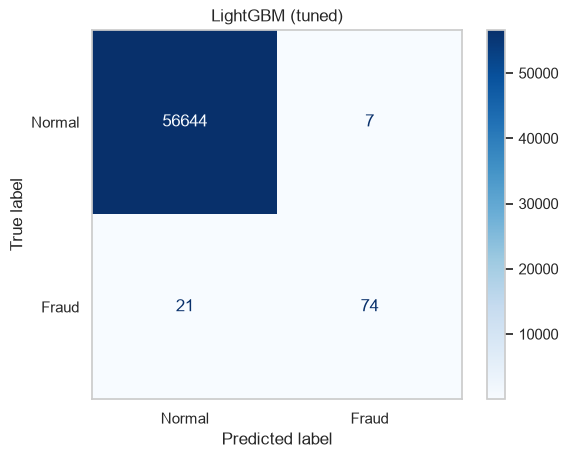

In [59]:
lgbm_param_dist = {
    "n_estimators": [300, 500, 800],
    "learning_rate": loguniform(0.01, 0.2),
    "num_leaves": [15, 31, 63, 127],
    "min_child_samples": [10, 20, 50, 100],
    "subsample": uniform(0.6, 0.4),
    "subsample_freq": [1],
    "colsample_bytree": uniform(0.5, 0.5),
    "reg_lambda": loguniform(1e-3, 10),
    "scale_pos_weight": [1, 5, 10, 25, 50, POS_WEIGHT],
}

# Each LightGBM fit uses 1 core; the search runs fits in parallel
lgbm_search = RandomizedSearchCV(
    make_lgbm(n_jobs=1), lgbm_param_dist, n_iter=25, scoring="average_precision",
    cv=cv, n_jobs=-1, random_state=RANDOM_STATE, verbose=1,
)

start = time.time()
lgbm_search.fit(X_train, y_train)
print(f"Search time: {time.time() - start:.0f} s")
print("Best params:", lgbm_search.best_params_)
print(f"Best CV PR-AUC: {lgbm_search.best_score_:.4f}")

lgbm_tuned = lgbm_search.best_estimator_
evaluate("LightGBM (tuned)", lgbm_tuned, X_test, y_test, lgbm_search.refit_time_);

### 10.4 Threshold tuning for the boosting models

Same method as Step 8: thresholds are chosen from out-of-fold probabilities on the training set, then applied once to the test set.

In [60]:
start = time.time()
xgb_oof = oof_probabilities(clone(xgb_tuned))
lgbm_oof = oof_probabilities(clone(lgbm_tuned).set_params(n_jobs=-1))
print(f"Done in {time.time() - start:.0f} s")

xgb_thr_f1, xgb_thr_rec, _ = choose_thresholds(y_train, xgb_oof)
lgbm_thr_f1, lgbm_thr_rec, _ = choose_thresholds(y_train, lgbm_oof)
print(f"XGBoost   -> best-F1 threshold: {xgb_thr_f1:.3f}, recall>=85% threshold: {xgb_thr_rec:.3f}")
print(f"LightGBM  -> best-F1 threshold: {lgbm_thr_f1:.3f}, recall>=85% threshold: {lgbm_thr_rec:.3f}")

Done in 12 s
XGBoost   -> best-F1 threshold: 0.877, recall>=85% threshold: 0.029
LightGBM  -> best-F1 threshold: 0.497, recall>=85% threshold: 0.059


=== XGBoost (tuned, thr=0.88, best F1) ===
              precision    recall  f1-score   support

      Normal     0.9996    1.0000    0.9998     56651
       Fraud     0.9863    0.7579    0.8571        95

    accuracy                         0.9996     56746
   macro avg     0.9929    0.8789    0.9285     56746
weighted avg     0.9996    0.9996    0.9995     56746



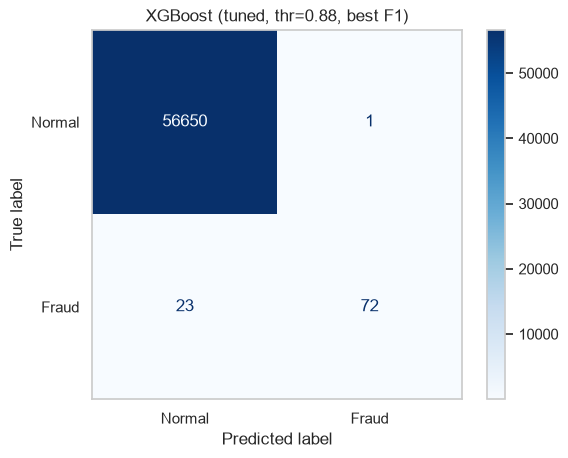

=== XGBoost (tuned, thr=0.03, recall≥85%) ===
              precision    recall  f1-score   support

      Normal     0.9997    0.9992    0.9995     56651
       Fraud     0.6349    0.8421    0.7240        95

    accuracy                         0.9989     56746
   macro avg     0.8173    0.9206    0.8617     56746
weighted avg     0.9991    0.9989    0.9990     56746



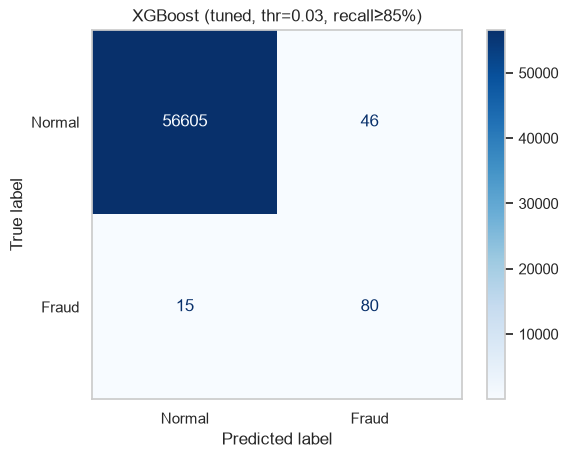

=== LightGBM (tuned, thr=0.50, best F1) ===
              precision    recall  f1-score   support

      Normal     0.9996    0.9999    0.9998     56651
       Fraud     0.9136    0.7789    0.8409        95

    accuracy                         0.9995     56746
   macro avg     0.9566    0.8894    0.9203     56746
weighted avg     0.9995    0.9995    0.9995     56746



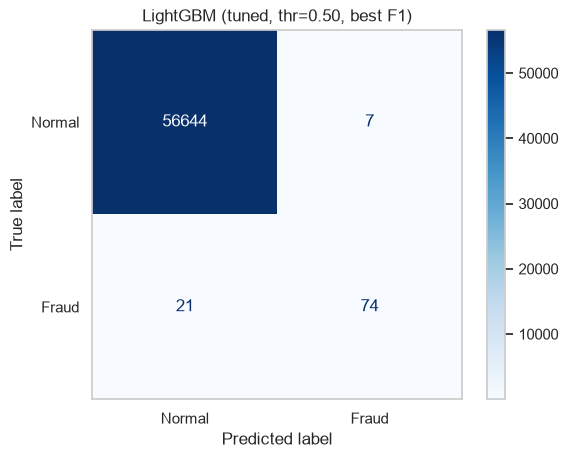

=== LightGBM (tuned, thr=0.06, recall≥85%) ===
              precision    recall  f1-score   support

      Normal     0.9997    0.9992    0.9994     56651
       Fraud     0.6190    0.8211    0.7059        95

    accuracy                         0.9989     56746
   macro avg     0.8094    0.9101    0.8527     56746
weighted avg     0.9991    0.9989    0.9989     56746



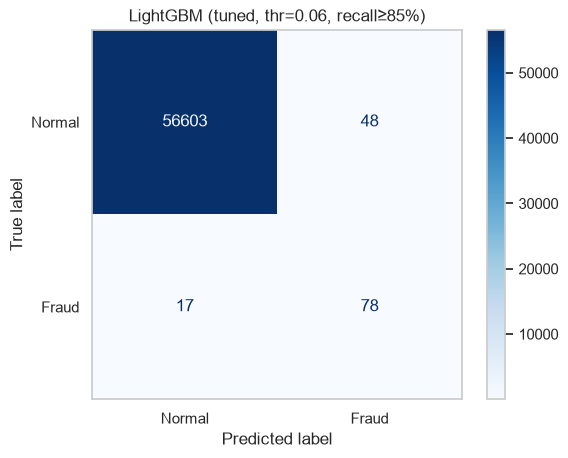

In [61]:
for name, model, t_f1, t_rec in [
    ("XGBoost (tuned", xgb_tuned, xgb_thr_f1, xgb_thr_rec),
    ("LightGBM (tuned", lgbm_tuned, lgbm_thr_f1, lgbm_thr_rec),
]:
    evaluate(f"{name}, thr={t_f1:.2f}, best F1)", ThresholdModel(model, t_f1), X_test, y_test)
    evaluate(f"{name}, thr={t_rec:.2f}, recall≥85%)", ThresholdModel(model, t_rec), X_test, y_test)

### 10.5 Comparison of all model families

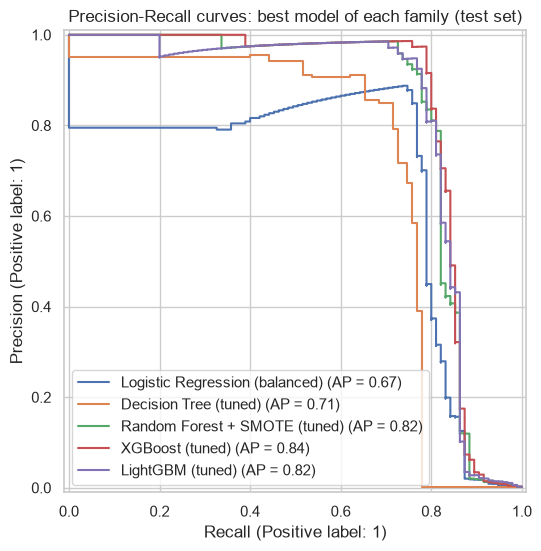

In [62]:
fig, ax = plt.subplots(figsize=(8, 6))
for name, model in [
    ("Logistic Regression (balanced)", lr),
    ("Decision Tree (tuned)", dt_tuned),
    ("Random Forest + SMOTE (tuned)", rf_tuned),
    ("XGBoost (tuned)", xgb_tuned),
    ("LightGBM (tuned)", lgbm_tuned),
]:
    PrecisionRecallDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.set_title("Precision-Recall curves: best model of each family (test set)")
plt.show()

In [63]:
results_df = pd.DataFrame(results).set_index("Model")
all_models_df = results_df[["Precision", "Recall", "F1", "PR-AUC", "ROC-AUC", "Train time (s)"]].round(4)
all_models_df.sort_values("PR-AUC", ascending=False)

,Precision,Recall,F1,PR-AUC,ROC-AUC,Train time (s)
Model,,,,,,
"XGBoost (tuned, thr=0.03, recall≥85%)",0.6349,0.8421,0.7240,0.8358,0.9756,NaN
"XGBoost (tuned, thr=0.88, best F1)",0.9863,0.7579,0.8571,0.8358,0.9756,NaN
XGBoost (tuned),0.9494,0.7895,0.8621,0.8358,0.9756,1.4450
XGBoost + scale_pos_weight,0.9359,0.7684,0.8439,0.8317,0.9795,1.3422
"Random Forest + SMOTE (tuned, thr=0.25, recall≥85%)",0.7222,0.8211,0.7685,0.8238,0.9749,NaN
"Random Forest + SMOTE (tuned, thr=0.64, best F1)",0.9459,0.7368,0.8284,0.8238,0.9749,NaN
Random Forest + SMOTE (tuned),0.9231,0.7579,0.8324,0.8238,0.9749,140.8998
LightGBM (tuned),0.9136,0.7789,0.8409,0.8212,0.9804,8.5819
"LightGBM (tuned, thr=0.50, best F1)",0.9136,0.7789,0.8409,0.8212,0.9804,NaN


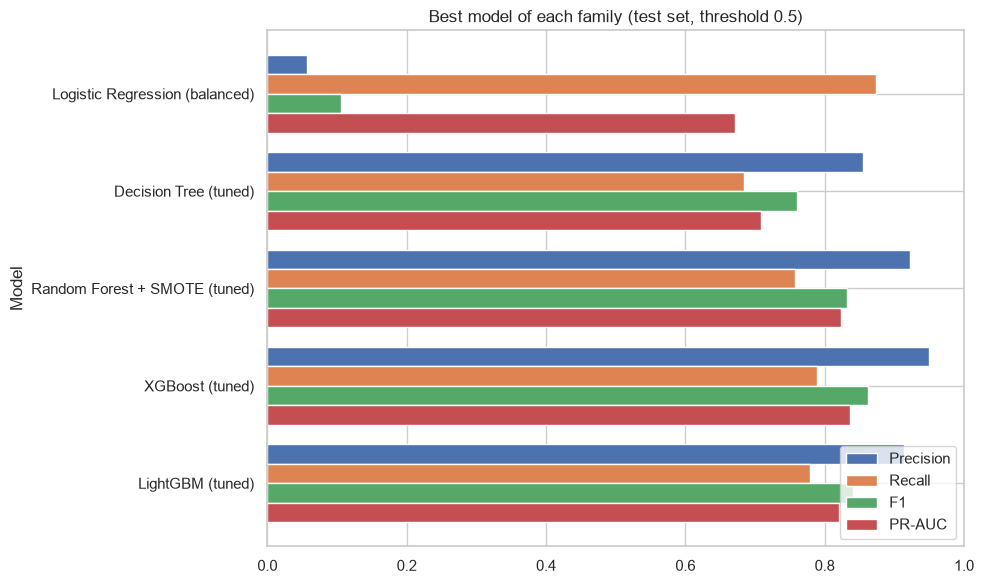

In [64]:
family_best = [
    "Logistic Regression (balanced)",
    "Decision Tree (tuned)",
    "Random Forest + SMOTE (tuned)",
    "XGBoost (tuned)",
    "LightGBM (tuned)",
]
ax = results_df.loc[family_best, ["Precision", "Recall", "F1", "PR-AUC"]].plot(kind="barh", figsize=(10, 6), width=0.8)
ax.set_xlim(0, 1)
ax.invert_yaxis()
ax.set_title("Best model of each family (test set, threshold 0.5)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Observations

- **Logistic Regression** is clearly weaker (PR-AUC 0.67–0.69). With class weights it catches 87% of frauds but precision is only 5.6%; without weights precision is 85% but recall drops to 58%. A linear model cannot separate fraud as well as tree ensembles.
- **XGBoost is the best model overall.** Tuned on the GPU it reaches PR-AUC **0.836** and F1 **0.862** (75 of 95 frauds caught with only 4 false alarms). Even the untuned baseline (PR-AUC 0.820, F1 0.852) beats the tuned Random Forest on F1. The whole 75-fit search took just 67 s on the RTX 3050.
- **LightGBM is very sensitive to settings on this data.** Its defaults performed poorly (precision 0.26), and the full `scale_pos_weight` (~600) made it worse (precision 0.02). After tuning (small trees, low learning rate, `scale_pos_weight=10`) it is competitive: PR-AUC 0.821 and the highest ROC-AUC (0.980).
- **Threshold tuning on XGBoost** gives two useful operating points:
  - threshold **0.88**: precision **0.986** (72 frauds caught, 1 false alarm), for when false alarms are costly;
  - threshold **0.03**: recall **0.842** (80 frauds caught, ~46 false alarms), for when missing fraud is costly.
- The boosting and Random Forest models are close (PR-AUC 0.82–0.84). With only 95 test frauds, differences of 1–3 cases are within noise, so the ranking of these top models is not certain.

## Final Conclusion

| Family | Best version | Precision | Recall | F1 | PR-AUC |
|---|---|---|---|---|---|
| Logistic Regression | no weighting | 0.846 | 0.579 | 0.688 | 0.692 |
| Decision Tree | tuned | 0.855 | 0.684 | 0.760 | 0.709 |
| Random Forest | + SMOTE, tuned | 0.923 | 0.758 | 0.832 | 0.824 |
| LightGBM | tuned | 0.914 | 0.779 | 0.841 | 0.821 |
| **XGBoost** | **tuned (GPU)** | **0.949** | **0.789** | **0.862** | **0.836** |

1. **Accuracy is useless here**: every model scores ≈99.9%. PR-AUC, precision, recall and F1 on the fraud class are the meaningful metrics.
2. **Ensembles beat single models.** Performance improves from linear → single tree → bagging (Random Forest) → boosting (XGBoost).
3. **Imbalance handling must be tuned, not just switched on.** Full balancing (undersampling, full class weights) raised recall but destroyed precision for most models; the best results came from *light* rebalancing (SMOTE ratio 0.1 for the Random Forest, `scale_pos_weight=10` for LightGBM).
4. **Hyperparameter and threshold tuning matter.** Tuning raised Decision Tree PR-AUC from 0.51 to 0.71, and threshold tuning lets the bank choose between ~99% precision and ~84% recall with the same model.
5. **Best model: tuned XGBoost**, catching 79% of frauds with 95% precision at the default threshold. Among the two required models, the **Random Forest** clearly beats the Decision Tree.
6. The most important features (`V14`, `V17`, `V10`, `V12`, `V16`) agree with the EDA correlations.

**Limitations:** only 95 frauds in the test set, so small differences between the top models are not statistically reliable; features are anonymised PCA components, so they cannot be interpreted in business terms; the data covers only two days of transactions.